In [1]:
import matplotlib.pyplot as plt
import numpy as np 
import os 
from pathlib import Path 
import torch 
from typing import *

class ActivationParser:
    def __init__(self, root: Path, layer_prefix: str, task_mapping: dict = None):
        self.root = root if isinstance(root, Path) else Path(root)
        self.layer_prefix = layer_prefix
        self.task_mapping = task_mapping or {}
        self.task_to_idx = {v: k for k, v in self.task_mapping.items()}
        self.expert_infix = 'mlp.experts'
        self.gate_infix = 'mlp.gate'
        self.expert_to_idx_num = {task: {} for task in self.task_mapping}
      
    def parse_experts(self, layer: int, task='', as_gen=False):
        gen = self._parse_kind(layer, task)
        if as_gen:
            return gen 
        return dict(gen)
    
    def parse_gate(self, layer: int, task=''):
        # return next(iter(self._parse_kind(layer, task, self.gate_infix)))[1]
        path: Path = f'{self.layer_prefix}.{layer}.{self.gate_infix}'
        task = self.task_mapping.get(task, 0)
        for expert in self.root.iterdir():
            if not expert.name.endswith(self.gate_infix):
                continue
            file = expert /  f'{task}.pth'
            t = torch.load(file).cpu()
            return t
        raise Exception('no gate found')

    def _parse_kind(self, layer, task):
        path: Path = f'{self.layer_prefix}.{layer}.{self.expert_infix}'
        task = self.task_to_idx[task]
        for expert in self.root.iterdir():
            if not str(path) in expert.name:
                continue
            n = int(expert.name.split('.')[-1])
            file = expert /  f'{task}.pth'
            if file.exists():
                t = torch.load(file).cpu()
                self.expert_to_idx_num[task][n] = t.size(0)
                yield n, t

    def get_experts_per_token(self, gate_output, k=4):
        return torch.topk(gate_output, k, dim=-1).indices
    
    def count_expert_calls(self, experts: Dict[int, torch.Tensor]):
        return {expert: value.size(0) for expert, value in experts.items()}
  
    def get_token_routing_map(self, layer: int, task: str = '', k: int = 4):
        """
        Returns a list of length = num_tokens.
        For each token i:
            token_routing[i] = list of tuples: (expert_id, row_idx_in_expert_tensor, gate_weight)
        
        gate_weight = softmax of the top-k logits for that token-expert pair
        (standard Mixtral / DeepSeek / most modern MoE routing)
        """
        gate_output = self.parse_gate(layer, task)          # (num_tokens, num_experts)
        n_tokens = gate_output.shape[0]
        num_experts = gate_output.shape[1]

        # 1. Get top-k experts + raw scores
        topk_values, topk_indices = torch.topk(gate_output, k, dim=-1)   # both (n_tokens, k)

        # 2. Convert raw top-k scores → actual routing weights (softmax per token)
        routing_weights = torch.softmax(topk_values, dim=-1)             # (n_tokens, k)

        # 3. Build per-expert list of tokens that were routed to it
        expert_to_tokens = [[] for _ in range(num_experts)]
        for t in range(n_tokens):
            for i in range(k):
                e = topk_indices[t, i].item()
                expert_to_tokens[e].append(t)

        # 4. For each expert, sort tokens by original index (this matches how activations are saved)
        expert_to_sorted_tokens = [sorted(tok_list) for tok_list in expert_to_tokens]

        # 5. Fast lookup: token → row index inside that expert's tensor
        expert_to_token2row = []
        for e in range(num_experts):
            token2row = {token: row_idx for row_idx, token in enumerate(expert_to_sorted_tokens[e])}
            expert_to_token2row.append(token2row)

        # 6. Build final map
        token_routing = []
        for t in range(n_tokens):
            token_list = []
            for i in range(k):
                e = topk_indices[t, i].item()
                weight = routing_weights[t, i].item()
                row_idx = expert_to_token2row[e][t]
                token_list.append((e, row_idx, weight))
            token_routing.append(token_list)

        return token_routing
           



In [2]:
mapping = dict(zip(range(10), [
           "anatomy", 
            "conceptual_physics",
            "human_sexuality",
            "machine_learning", 
            "management", 
            "marketing", 
            "nutrition",
             "philosophy",
            "us_foreign_policy",
              "world_religions"
]
))

In [3]:
parser = ActivationParser('activations_moe', 'model.layers', mapping)

In [4]:
experts_a = parser.parse_experts(0, 'anatomy')
experts_p = parser.parse_experts(0, 'philosophy')


In [5]:
def get_indices_from_gate(gate: torch.Tensor, exp_to_k: dict, total_experts: int):
    exp_to_indices = {}
    exp_to_gate_values = {}
    for i in range(total_experts):
        k = exp_to_k.get(i, 0)
        topk = torch.topk(gate[:, i], k)
        exp_to_gate_values[i] = topk.values
        exp_to_indices[i] = topk.indices
    indices_in_batch = {}
    for exp, indices in exp_to_indices.items():
        indices_in_initial_order = torch.sort(indices, descending=False).values
        indices_in_batch[exp] = torch.argsort(gate[indices_in_initial_order, exp], descending=True)
    return exp_to_indices, exp_to_gate_values, indices_in_batch

In [6]:
import pandas as pd
from typing import *


def map_expert_to_max_activation(token_routing):
    expert2maxrow = {} 
    for token in token_routing:
        for expert in token:
            exp_idx = expert[0]
            if not exp_idx in expert2maxrow:
                expert2maxrow[exp_idx] = expert[1:]
            elif expert2maxrow[exp_idx][-1] < expert[-1]:
                expert2maxrow[exp_idx] = expert[1:] 

    for exp in expert2maxrow:
        expert2maxrow[exp] = expert2maxrow[exp][0]
    return expert2maxrow 


def get_tasks_expert_embeddings(parser: ActivationParser, tasks: List[str], aggregation: Literal['mean', 'max'], layers=None):
    res = []
    layers = layers or [0]

    for task in tasks:
        print(task, '!!!')
        for layer in layers:
            experts = parser.parse_experts(layer, task)

            if aggregation == 'max':
                embeddings = {e: activations[torch.argmax(torch.linalg.norm(activations, dim=-1))] for e, activations in experts.items()}
            elif aggregation == 'mean':
                embeddings = {e: torch.mean(e_vals, dim=0) for e, e_vals in experts.items()}
            else:
                raise ValueError(f'Unknown aggregation: {aggregation}. Supported max, mean')
            for expert, embedding in embeddings.items():
                res.append(
                    (task, layer, expert, *embedding.cpu().numpy())
                )
    res = pd.DataFrame(res, columns=('task', 'layer', 'expert', *[f'emb_{i}' for i in range(len(res[-1]) - 3)]))
    return res 



In [7]:
SELECTED_TASKS = ["anatomy", 
            # "conceptual_physics",
            # "human_sexuality",
            "machine_learning", 
            "management", 
            # "marketing", 
            # "nutrition",
             "philosophy",
            # "us_foreign_policy",
              "world_religions"]

In [8]:
embeddings = get_tasks_expert_embeddings(parser, ["anatomy", 
            # "conceptual_physics",
            # "human_sexuality",
            "machine_learning", 
            "management", 
            # "marketing", 
            # "nutrition",
             "philosophy",
            # "us_foreign_policy",
              "world_religions"], 'mean', range(60))

anatomy !!!
machine_learning !!!
management !!!
philosophy !!!
world_religions !!!


In [10]:
embs_only = embeddings.drop(['task', 'layer', 'expert'], axis=1)

In [11]:
from sklearn.decomposition import PCA 

pca = PCA(random_state=1).fit(embs_only)

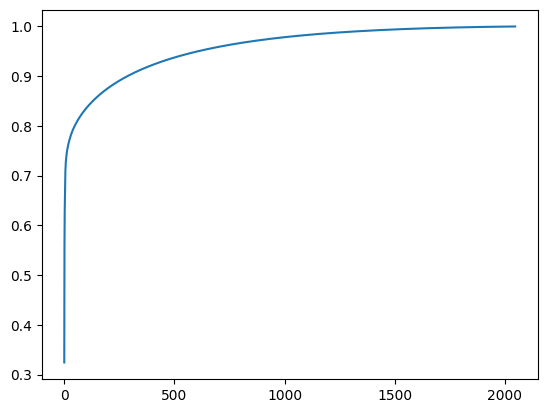

In [10]:
plt.plot(np.cumsum(pca.explained_variance_ratio_))

In [11]:
pca = PCA(64, random_state=1)

In [12]:
embs_only = pca.fit_transform(embs_only)

In [13]:
np.sum(pca.explained_variance_ratio_)

np.float64(0.8125795472894699)

Можно обрезать до 512 ГК без особой потери разнообразия

In [14]:
# update embeddings 

embeddings_ = embeddings[['task', 'layer', 'expert']] 
embeddings_.loc[:, [f'emb_{i}' for i in range(embs_only.shape[-1])]] = embs_only

## mean aggregation by tokens

In [15]:
from sklearn.manifold import TSNE 

tsne = TSNE(random_state=1, perplexity=30)
reducted_embeddings = tsne.fit_transform(embs_only)

In [16]:
reducted_embeddings = tsne.fit_transform(embs_only)

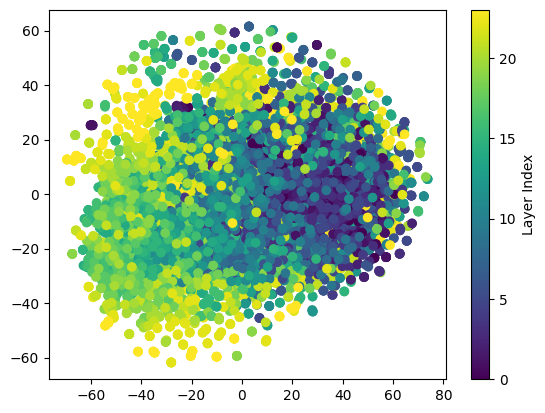

In [17]:
import matplotlib.pyplot as plt 

scatter = plt.scatter(*reducted_embeddings.T, c=embeddings['layer'])
plt.colorbar(scatter, label='Layer Index')


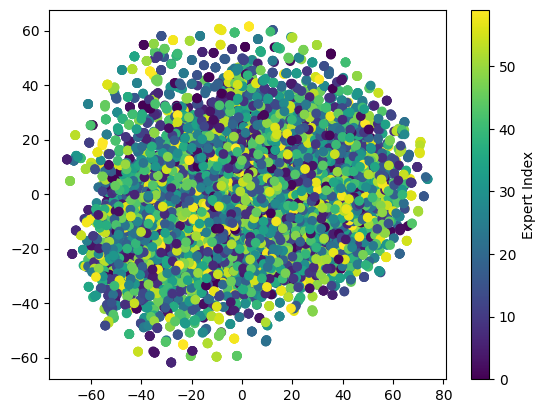

In [18]:
import matplotlib.pyplot as plt 

scatter = plt.scatter(*reducted_embeddings.T, c=embeddings['expert'])
plt.colorbar(scatter, label='Expert Index')

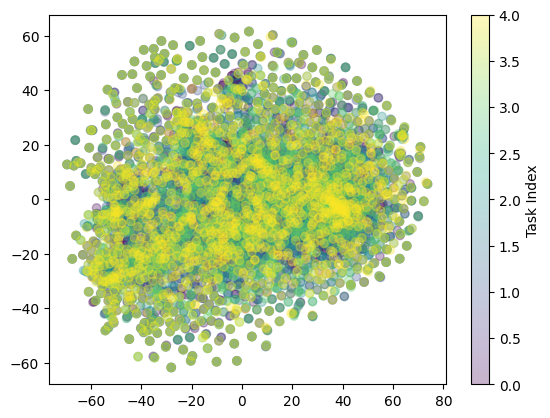

In [19]:
scatter = plt.scatter(*reducted_embeddings.T, c=embeddings['task'].map(dict(zip(embeddings.task.unique(), range(100000)))), alpha=0.3)
plt.colorbar(scatter, label='Task Index')

/home/leostre/Рабочий стол/MoE_Optimization/.venv/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


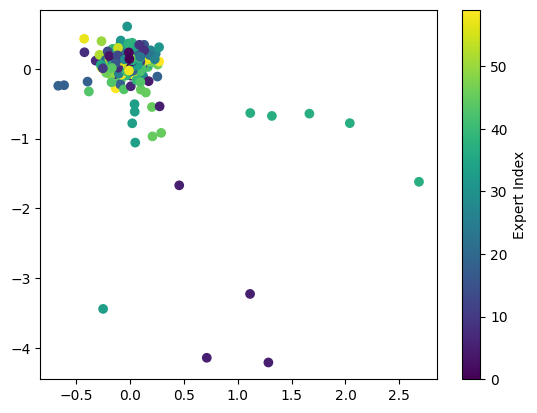

/home/leostre/Рабочий стол/MoE_Optimization/.venv/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


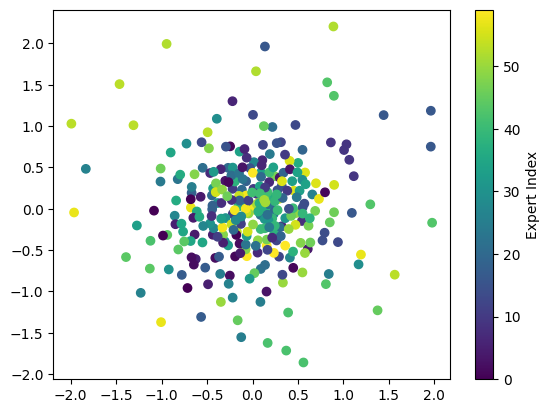

/home/leostre/Рабочий стол/MoE_Optimization/.venv/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


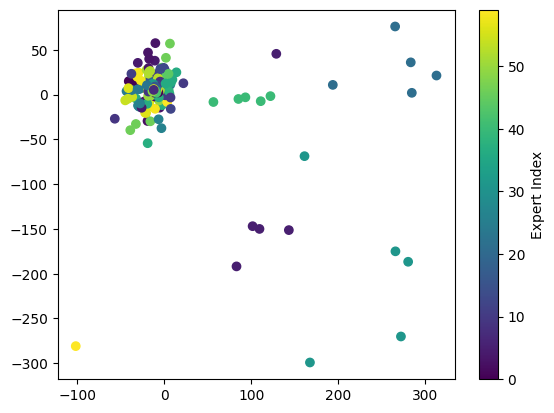

In [20]:
from sklearn.manifold import TSNE, Isomap, MDS

for layer in [0, 11, 23]:
    tsne = MDS()
    mask = embeddings.layer == layer
    reducted_embeddings = tsne.fit_transform(embs_only[mask])
    c = embeddings['expert'][mask]
    scatter = plt.scatter(*reducted_embeddings.T, c=c)
    plt.colorbar(scatter, label='Expert Index')
    plt.show()
    

/home/leostre/Рабочий стол/MoE_Optimization/.venv/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


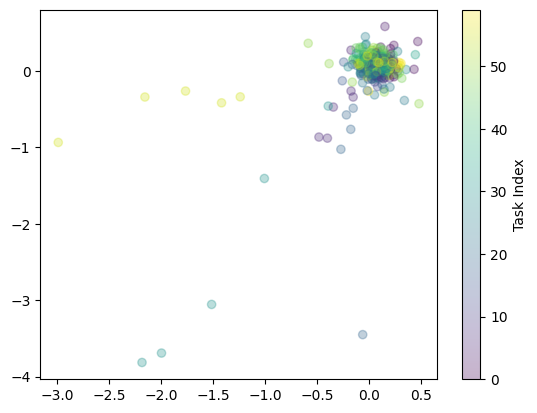

/home/leostre/Рабочий стол/MoE_Optimization/.venv/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


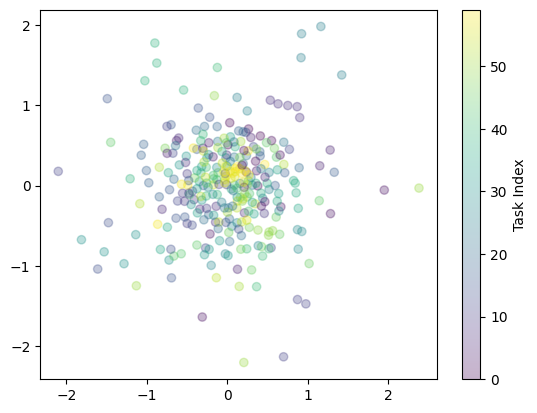

/home/leostre/Рабочий стол/MoE_Optimization/.venv/lib/python3.10/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


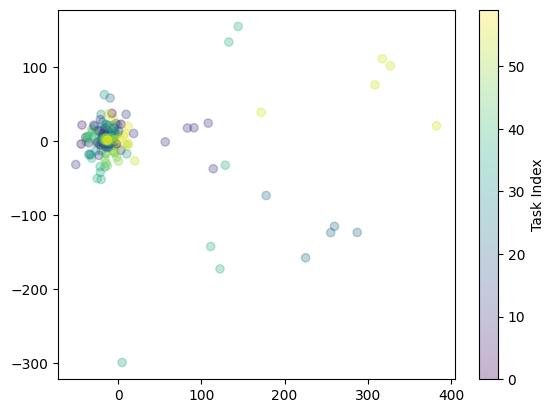

In [21]:
from sklearn.manifold import TSNE


for layer in [0, 11, 23]:
    tsne = MDS()
    mask = embeddings.layer == layer
    reducted_embeddings = tsne.fit_transform(embs_only[mask])
    c = embeddings['expert'][mask]
    scatter = plt.scatter(*reducted_embeddings.T, c=c.map(dict(zip(c.unique(), range(100000)))), alpha=0.3)
    plt.colorbar(scatter, label='Task Index')

    plt.show()

In [22]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, Birch, OPTICS
from sklearn.mixture import GaussianMixture
import hdbscan
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

def evaluate_clustering_metrics(X, labels):
    # Filter out noise points (-1) for metrics that don't handle them
    mask = labels != -1
    if mask.sum() > 1:
        X_clean = X[mask]
        labels_clean = labels[mask]
        
        metrics = {
            'silhouette': silhouette_score(X_clean, labels_clean),
            'calinski_harabasz': calinski_harabasz_score(X_clean, labels_clean),
            'davies_bouldin': davies_bouldin_score(X_clean, labels_clean),
            'n_clusters': len(set(labels_clean)),
            'noise_points': (labels == -1).sum()
        }
        return metrics
    return None

def estimate_clustering(df, task, layer=None):
    df = df[(df.task == task)]
    if layer:
        df = df[df.layer == layer]
    df = df.drop(['expert', 'layer', 'task'], axis=1)
    assert len(df)
    n_clusters = 8 # double activation_per_token

    # Try different algorithms
    algorithms = {
        'kmeans': KMeans(n_clusters=n_clusters, random_state=42),
        # 'gmm': GaussianMixture(n_components=n_clusters, random_state=42),
        'agglomerative': AgglomerativeClustering(n_clusters=n_clusters),
        'birch': Birch(n_clusters=n_clusters), 
        # 'hdbscan': HDBSCAN(min_cluster_size=5, min_samples=1)
    }

    results_mean = {}
    for name, algorithm in algorithms.items():
        print(name, 'started...')
        labels = algorithm.fit_predict(df)
        # results_mean[name] = labels
        assert len(labels) == df.shape[0]
        results = evaluate_clustering_metrics(df, labels)
        results_mean[name] = results

    return pd.DataFrame(results_mean)
    

In [23]:
def cluster_metrics_by_task(embeddings, layer):
    metrics = []
    for task in embeddings.task.unique():
        task_metrics = estimate_clustering(embeddings, task, layer).reset_index().melt(
            id_vars='index', 
            var_name='clustering_algo', 
            value_name='value'
        ).rename(columns={'index': 'metric'})
        task_metrics['task'] = task 
        metrics.append(task_metrics)
    return pd.concat(metrics, axis=0)
    

In [24]:
metrics0 = cluster_metrics_by_task(embeddings_, 0)

kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...


In [25]:
metrics11 = cluster_metrics_by_task(embeddings_, 11)

kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...


In [26]:
metrics23 = cluster_metrics_by_task(embeddings_, 23)

kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...


In [27]:
metrics_all = cluster_metrics_by_task(embeddings_, None)

kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...


In [28]:
metrics0

,metric,clustering_algo,value,task
0,silhouette,kmeans,0.933097,anatomy
1,calinski_harabasz,kmeans,1113.000894,anatomy
2,davies_bouldin,kmeans,0.020016,anatomy
3,n_clusters,kmeans,8.000000,anatomy
4,noise_points,kmeans,0.000000,anatomy
...,...,...,...,...
10,silhouette,birch,0.938213,world_religions
11,calinski_harabasz,birch,1832.556969,world_religions
12,davies_bouldin,birch,0.110599,world_religions
13,n_clusters,birch,8.000000,world_religions


In [29]:
import seaborn as sns 

def barplot_metrics(melted_df):
    unique_metrics = melted_df['metric'].unique()


    for i, metric in enumerate(unique_metrics):
        if metric in ('n_clusters', 'noise_points'):
            continue
        # Filter data for current metric
        metric_data = melted_df[melted_df['metric'] == metric]
        
        # Create grouped barplot
        sns.barplot(
            data=metric_data,
            x='task',
            y='value',
            hue='clustering_algo',
            palette='Set2'
        )
        
        # Customize each subplot
        plt.title(f'{metric}')
        plt.xlabel('Task')
        plt.ylabel('Value')
        plt.legend(title='Clustering Algo', bbox_to_anchor=(1.05, 1), loc='upper left')
        
        # Rotate x-axis labels if needed
        plt.tick_params(axis='x', rotation=45)

        plt.tight_layout()
        plt.show()

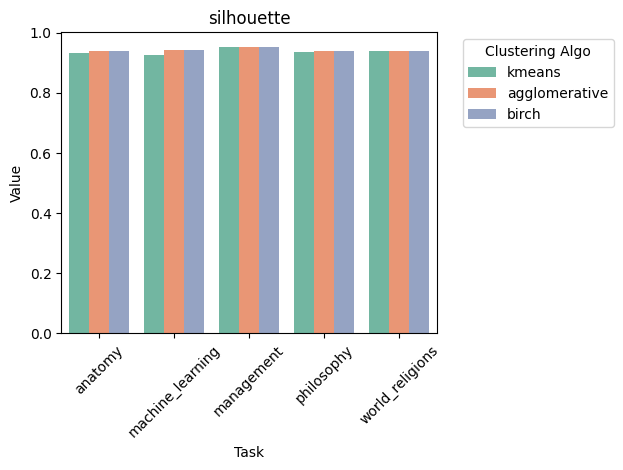

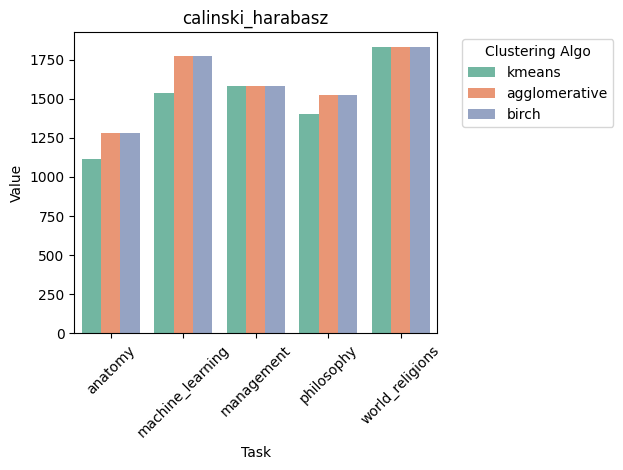

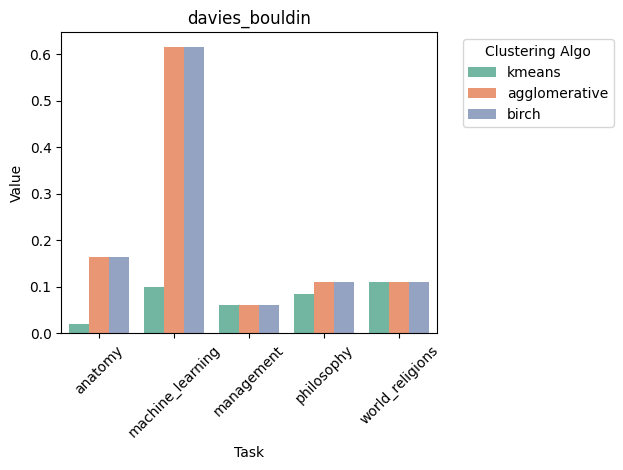

In [30]:
barplot_metrics(metrics0)

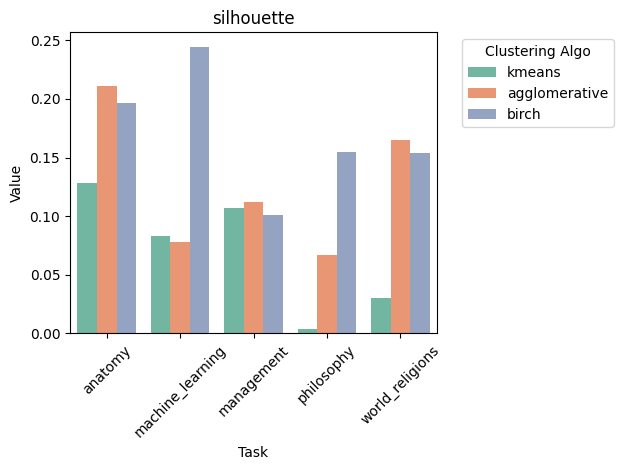

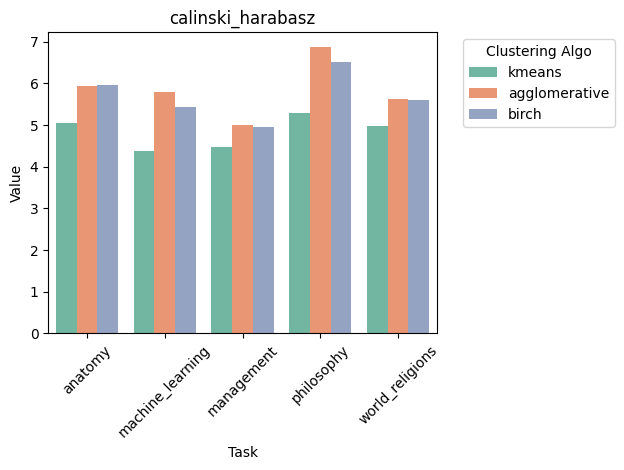

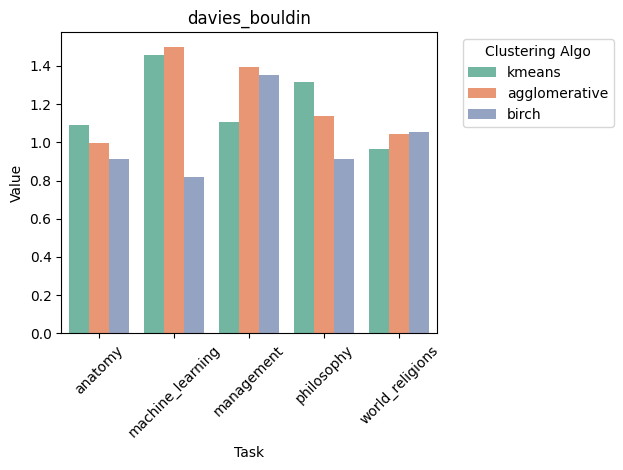

In [31]:
barplot_metrics(metrics11)

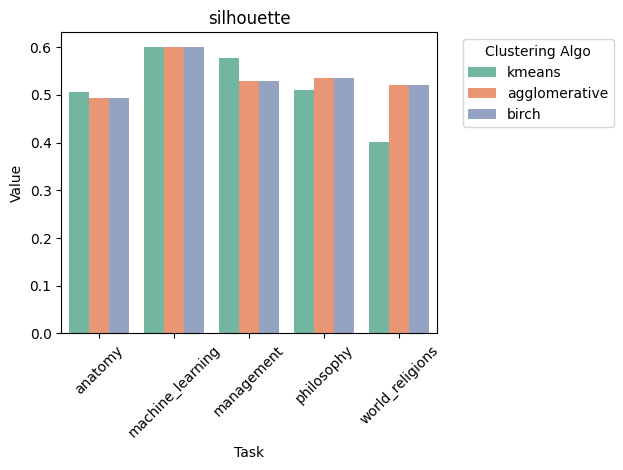

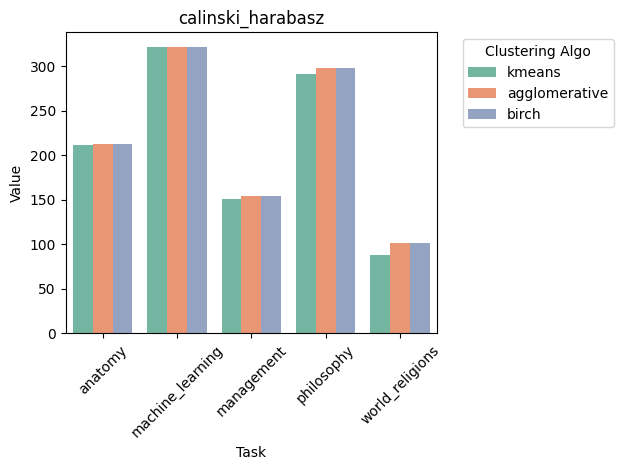

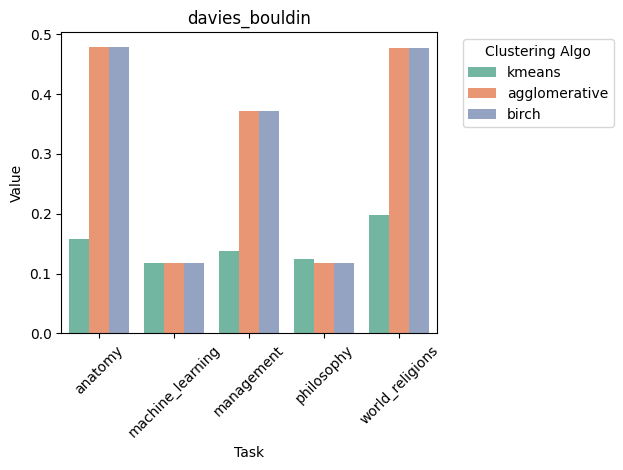

In [32]:
barplot_metrics(metrics23)

### Матрица экспертов и её спектры

In [33]:
embeddings

/home/leostre/Рабочий стол/MoE_Optimization/.venv/lib/python3.10/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()
/home/leostre/Рабочий стол/MoE_Optimization/.venv/lib/python3.10/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,task,layer,expert,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,...,emb_2038,emb_2039,emb_2040,emb_2041,emb_2042,emb_2043,emb_2044,emb_2045,emb_2046,emb_2047
0,anatomy,0,49,0.006840,-0.022202,0.043274,-0.008469,0.004543,0.015121,-0.022430,...,-0.038147,-0.008469,0.015121,0.013977,-0.012024,0.003902,0.009148,-0.032166,0.002834,-0.020599
1,anatomy,0,31,-0.002235,0.014336,-0.000842,-0.025787,0.003002,0.013557,0.037018,...,-0.021271,-0.040771,-0.040680,-0.039673,-0.051392,0.045013,0.009811,-0.037140,0.041016,0.006222
2,anatomy,0,30,-0.053406,0.002707,0.002613,-0.023102,0.027313,-0.064209,0.061401,...,0.055420,0.014008,-0.013977,0.007179,-0.028488,-0.042755,-0.000776,0.014450,0.007820,-0.017929
3,anatomy,0,57,0.000038,-0.030624,-0.021683,0.037384,-0.012993,-0.038940,0.008881,...,0.028015,-0.002375,-0.002161,0.020096,-0.010689,-0.002951,-0.001753,-0.021790,0.019928,0.005112
4,anatomy,0,14,-0.011681,-0.025192,0.001995,0.005089,-0.006290,0.001283,-0.017426,...,0.013863,0.008591,-0.014458,0.001797,-0.016434,-0.022263,0.001304,-0.005520,-0.010117,0.007175
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7132,world_religions,23,26,1.046875,-0.751953,-0.895996,-1.313477,0.975098,-0.298340,0.152344,...,-0.612305,0.638672,-0.439941,0.011185,-0.203247,0.820801,-0.005665,1.626953,-0.142212,-0.370117
7133,world_religions,23,31,2.867188,2.404297,2.101562,2.251953,3.876953,0.420898,-1.259766,...,-3.667969,-1.600586,-2.808594,-0.525879,-1.726562,2.720703,-3.376953,-1.629883,1.155273,2.574219
7134,world_religions,23,36,-0.194946,0.432861,0.224365,-0.137085,-0.031647,-0.570801,0.137329,...,0.298096,0.320557,0.115173,-0.019897,0.156128,0.166870,0.158325,-0.280273,0.061127,-0.440674
7135,world_religions,23,55,0.117920,0.048950,-0.250000,-0.146362,-0.036926,-0.150513,0.022461,...,-0.080688,0.040344,-0.001269,-0.132202,0.080505,0.058777,0.100220,0.001518,0.126221,-0.119812


In [34]:
from itertools import product

def get_expert_matrix(embeddings: pd.DataFrame, task, layer):
    return embeddings[(embeddings.task == task) & (embeddings.layer == layer)].drop(['task', 'layer', 'expert'], axis=1).values

def get_experts_spectra(embeddings, tasks, layers, n_experts=60, whiten=True):
    res = pd.DataFrame(columns=['task', 'layer', *[str(i) for i in range(n_experts)]])
    for task, layer in product(tasks, layers):
        whitened_matrix = get_expert_matrix(embeddings, task, layer).astype(np.float32)
        if whiten:
            whitened_matrix -= whitened_matrix.mean(axis=0)
        spectrum_ = np.linalg.svd(whitened_matrix, compute_uv=False)
        spectrum = np.zeros((n_experts,))
        spectrum[:len(spectrum_)] = spectrum_
        res.loc[len(res)] = (task, layer, *spectrum)
    return res 


In [35]:
spectra_mean = get_experts_spectra(embeddings, ["anatomy", 
            # "conceptual_physics",
            # "human_sexuality",
            "machine_learning", 
            "management", 
            # "marketing", 
            # "nutrition",
             "philosophy",
            # "us_foreign_policy",
              "world_religions"], [0, 5, 11, 17, 23], n_experts=60, whiten=True)

In [36]:
40 * 8 / 2.5 

128.0

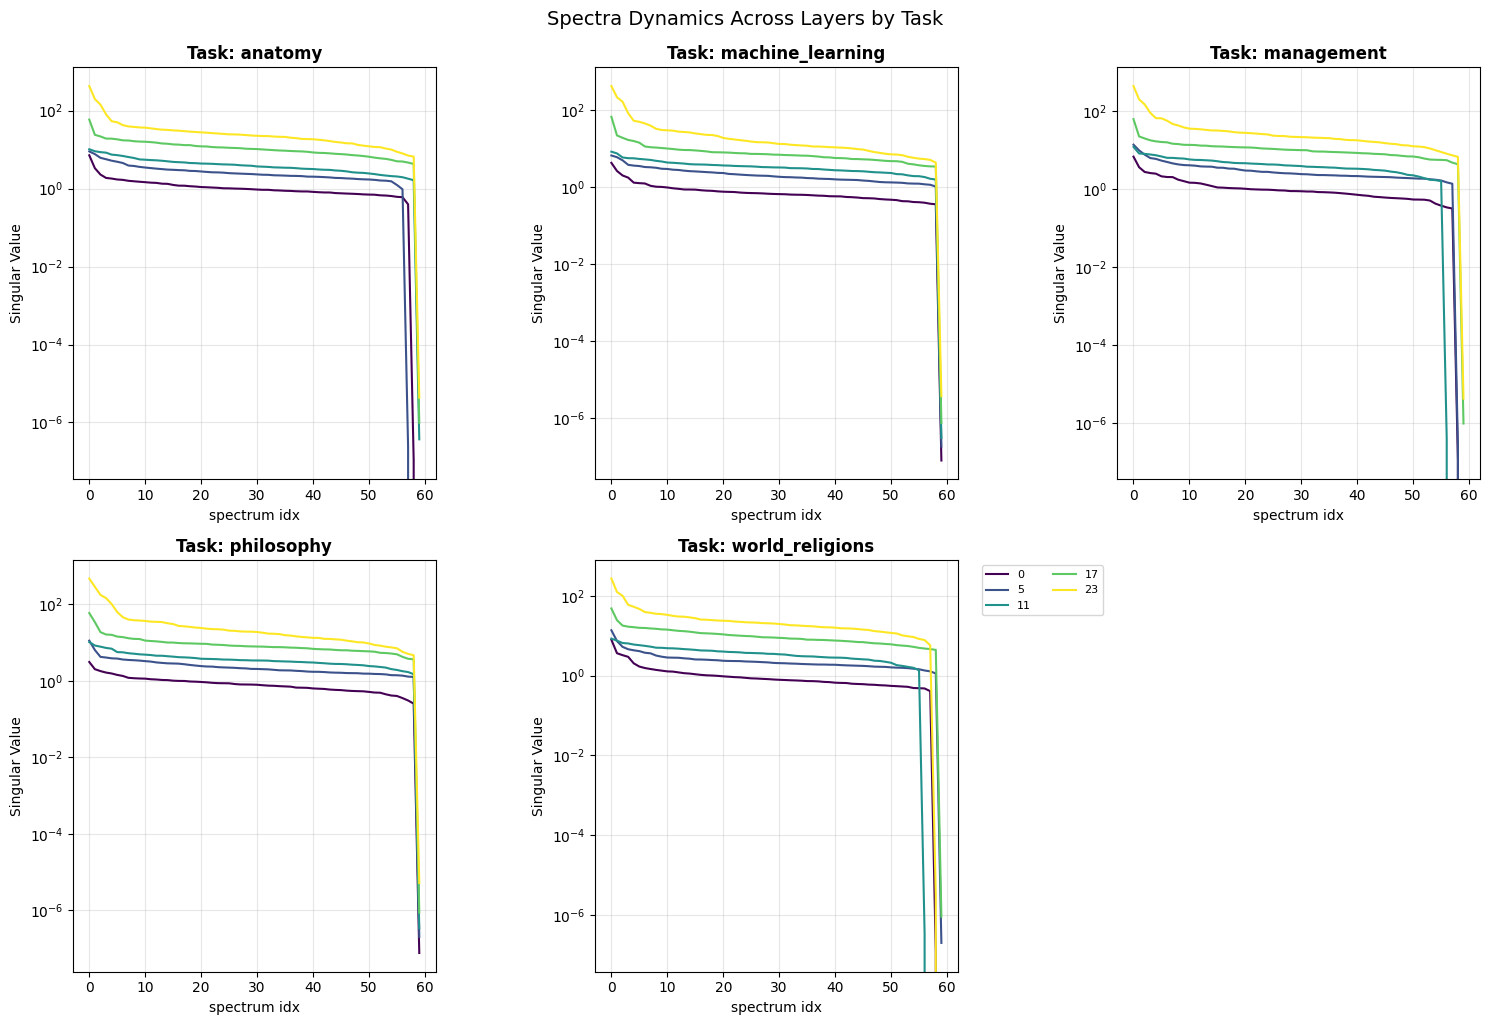

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_task_dynamics_line(df, figsize=(15, 10), log=True):
    """
    Plot dynamics for each task using line plots
    """
    # Get unique tasks
    tasks = df['task'].unique()
    n_tasks = len(tasks)
    layers = df['layer'].unique()
    
    # Calculate grid size
    n_cols = min(3, n_tasks)
    n_rows = (n_tasks + n_cols - 1) // n_cols
    
    # Create subplots
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)
    if n_tasks == 1:
        axes = np.array([axes])
    axes = axes.flatten()
    
    # Color palette for the 60 dimensions
    colors = plt.cm.viridis(np.linspace(0, 1, len(layers)))
    
    # Plot each task
    for idx, task in enumerate(tasks):
        ax = axes[idx]
        for color, layer in zip(colors, layers):
            spectrum = df[(df['task'] == task) & (df['layer'] == layer)].drop(['task', 'layer'], axis=1).values.flatten() 
            ax.plot(spectrum, c=color, label=str(layer))

        ax.set_title(f'Task: {task}', fontsize=12, fontweight='bold')
        ax.set_xlabel('spectrum idx', fontsize=10)
        ax.set_ylabel('Singular Value', fontsize=10)
        if log:
            ax.set_yscale('log')
        ax.grid(True, alpha=0.3)
    ax.legend(bbox_to_anchor=(1.05, 1), 
                      loc='upper left', 
                      ncol=2,
                      fontsize=8)
        
        # Set x-axis to show integer layers
        
    # Hide empty subplots
    for idx in range(len(tasks), len(axes)):
        axes[idx].set_visible(False)
    
    
    plt.tight_layout()
    
    # Add a single legend for all dimensions
    # if len(tasks) > 0:
    #     axes[0].legend(bbox_to_anchor=(1.05, 1), 
    #                   loc='upper left', 
    #                   ncol=2,
    #                   fontsize=8)
    
    plt.suptitle('Spectra Dynamics Across Layers by Task', y=1.02, fontsize=14)
    return fig

# Usage
fig = plot_task_dynamics_line(spectra_mean, log=True)
# plt.show()

## Max token 

In [38]:
parser

In [39]:
embeddings = get_tasks_expert_embeddings(parser, ["anatomy", 
            # "conceptual_physics",
            # "human_sexuality",
            "machine_learning", 
            "management", 
            # "marketing", 
            # "nutrition",
             "philosophy",
            # "us_foreign_policy",
              "world_religions"], 'max', range(60))

anatomy !!!
machine_learning !!!
management !!!
philosophy !!!
world_religions !!!


In [40]:
embeddings['task'].unique()

array(['anatomy', 'machine_learning', 'management', 'philosophy',
       'world_religions'], dtype=object)

In [41]:
embs_only = embeddings.drop(['task', 'layer', 'expert'], axis=1)

In [42]:
from sklearn.decomposition import PCA 

pca = PCA(random_state=1).fit(embs_only)

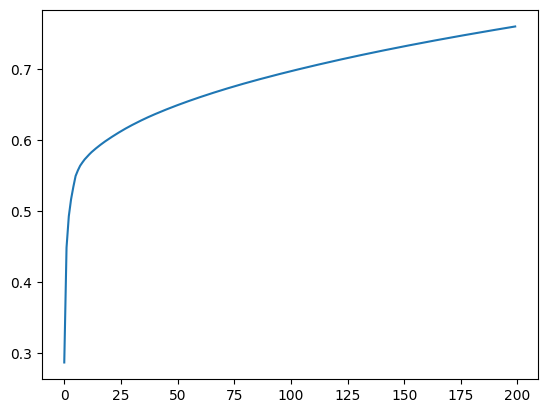

In [43]:
plt.plot(np.cumsum(pca.explained_variance_ratio_)[:200])

In [44]:
pca = PCA(64, random_state=1)

In [45]:
embs_only = pca.fit_transform(embs_only)

In [46]:
embeddings_ = embeddings[['task', 'layer', 'expert']] 
embeddings_.loc[:, [f'emb_{i}' for i in range(embs_only.shape[-1])]] = embs_only

In [47]:
from sklearn.manifold import TSNE 

tsne = TSNE(random_state=1, perplexity=30)
reducted_embeddings = tsne.fit_transform(embs_only)

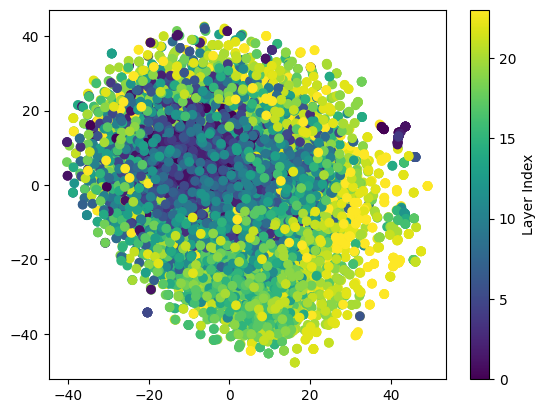

In [48]:
import matplotlib.pyplot as plt 

scatter = plt.scatter(*reducted_embeddings.T, c=embeddings['layer'])
plt.colorbar(scatter, label='Layer Index')

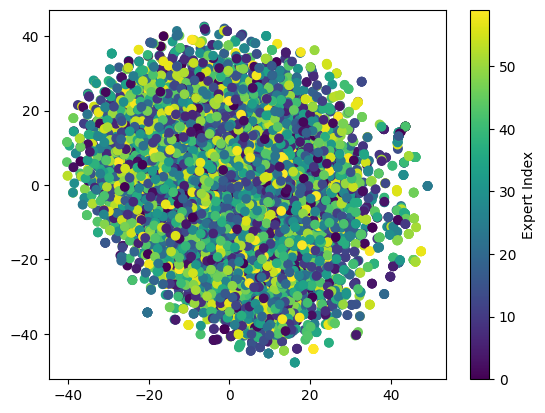

In [49]:
import matplotlib.pyplot as plt 

scatter = plt.scatter(*reducted_embeddings.T, c=embeddings['expert'])
plt.colorbar(scatter, label='Expert Index')

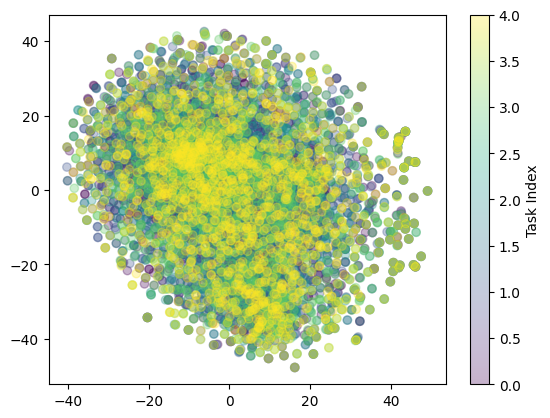

In [50]:
scatter = plt.scatter(*reducted_embeddings.T, c=embeddings['task'].map(dict(zip(embeddings.task.unique(), range(100000)))), alpha=0.3)
plt.colorbar(scatter, label='Task Index')

In [51]:
metrics0 = cluster_metrics_by_task(embeddings_, 0)

kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...


In [52]:
metrics11 = cluster_metrics_by_task(embeddings_, 11)

kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...


In [53]:
metrics23 = cluster_metrics_by_task(embeddings_, 23)

kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...
kmeans started...
agglomerative started...
birch started...


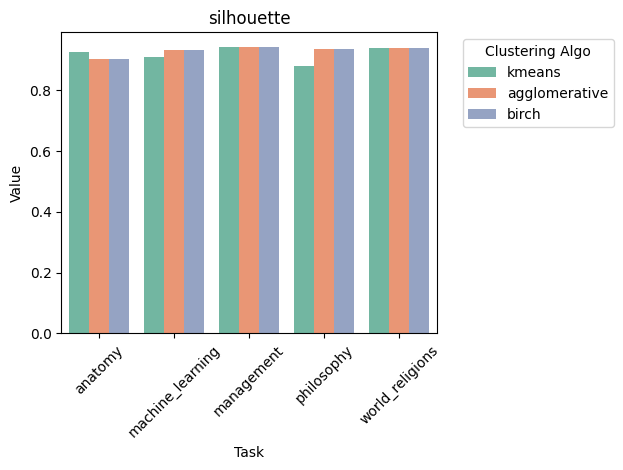

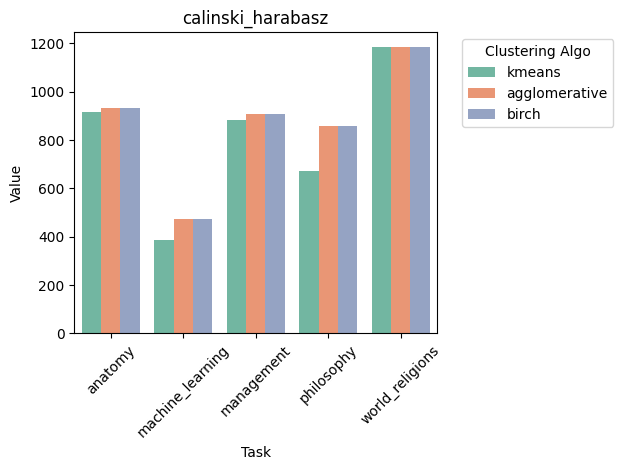

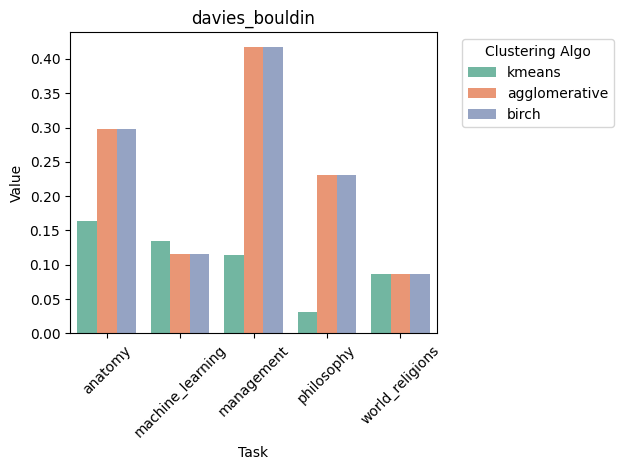

In [54]:
barplot_metrics(metrics0)

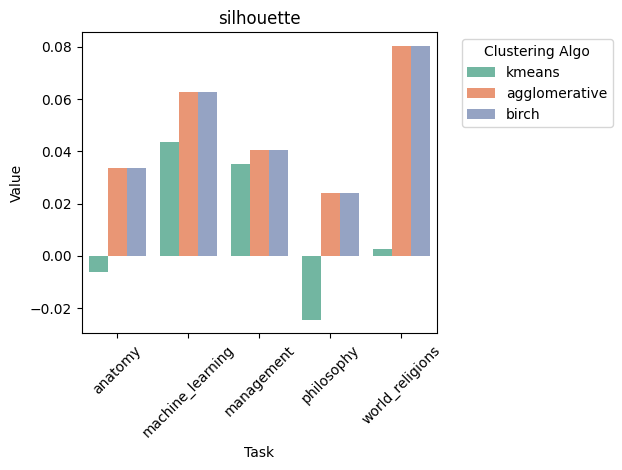

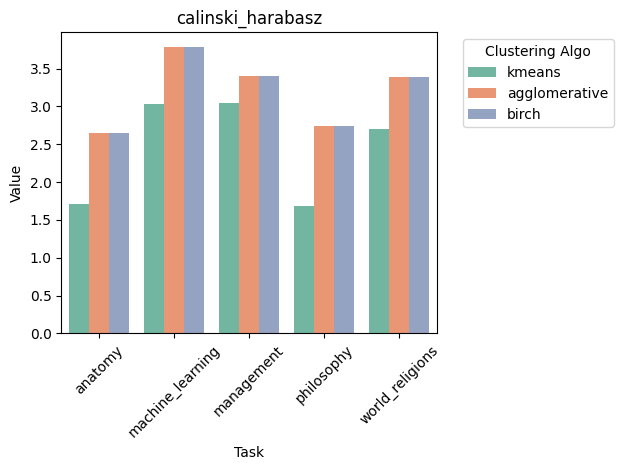

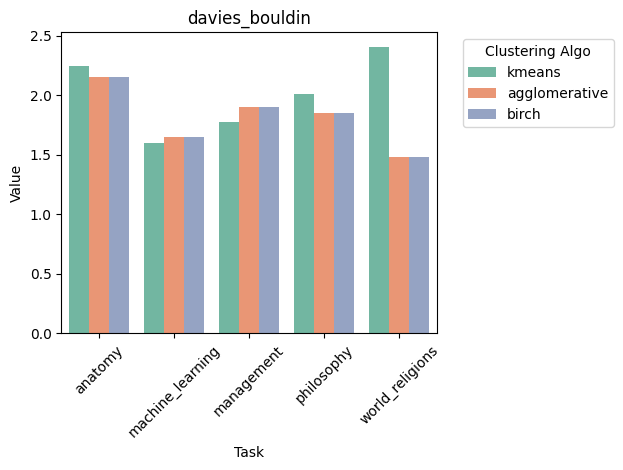

In [55]:
barplot_metrics(metrics11)

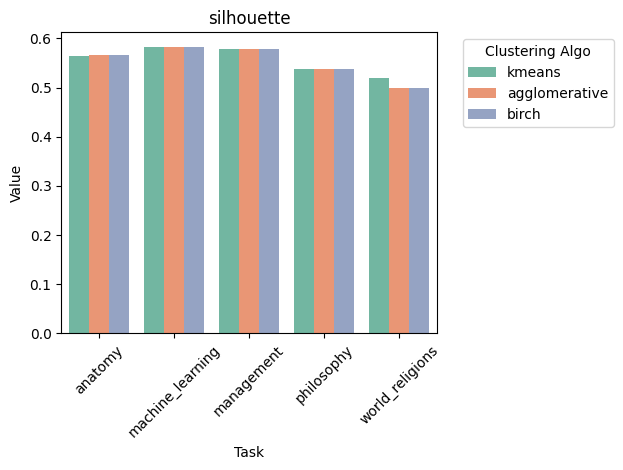

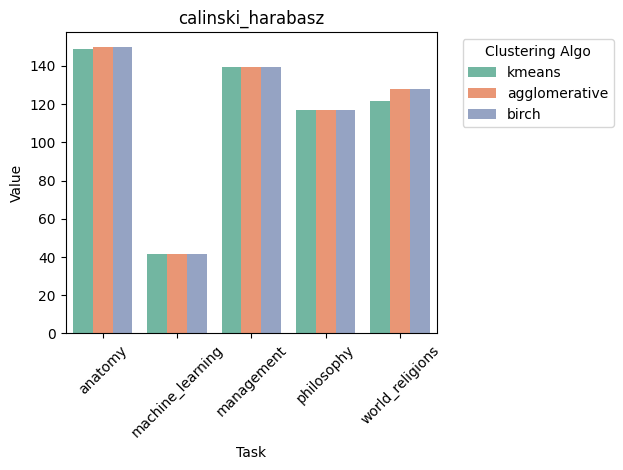

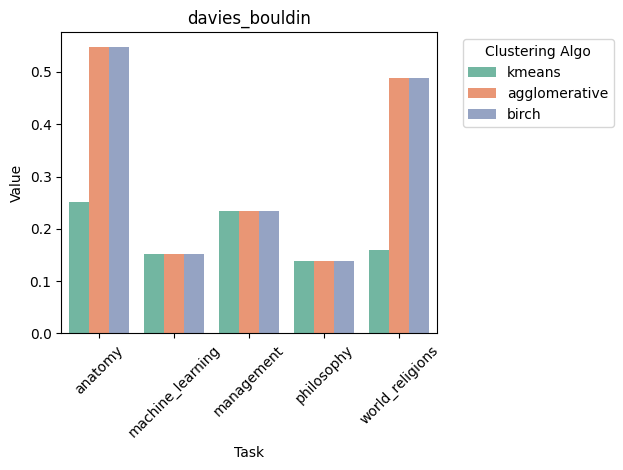

In [56]:
barplot_metrics(metrics23)

### Spectra

In [57]:
spectra_maxl2 = get_experts_spectra(embeddings, ["anatomy", 
            # "conceptual_physics",
            # "human_sexuality",
            "machine_learning", 
            "management", 
            # "marketing", 
            # "nutrition",
             "philosophy",
            # "us_foreign_policy",
              "world_religions"], [0, 5, 11, 17, 23])

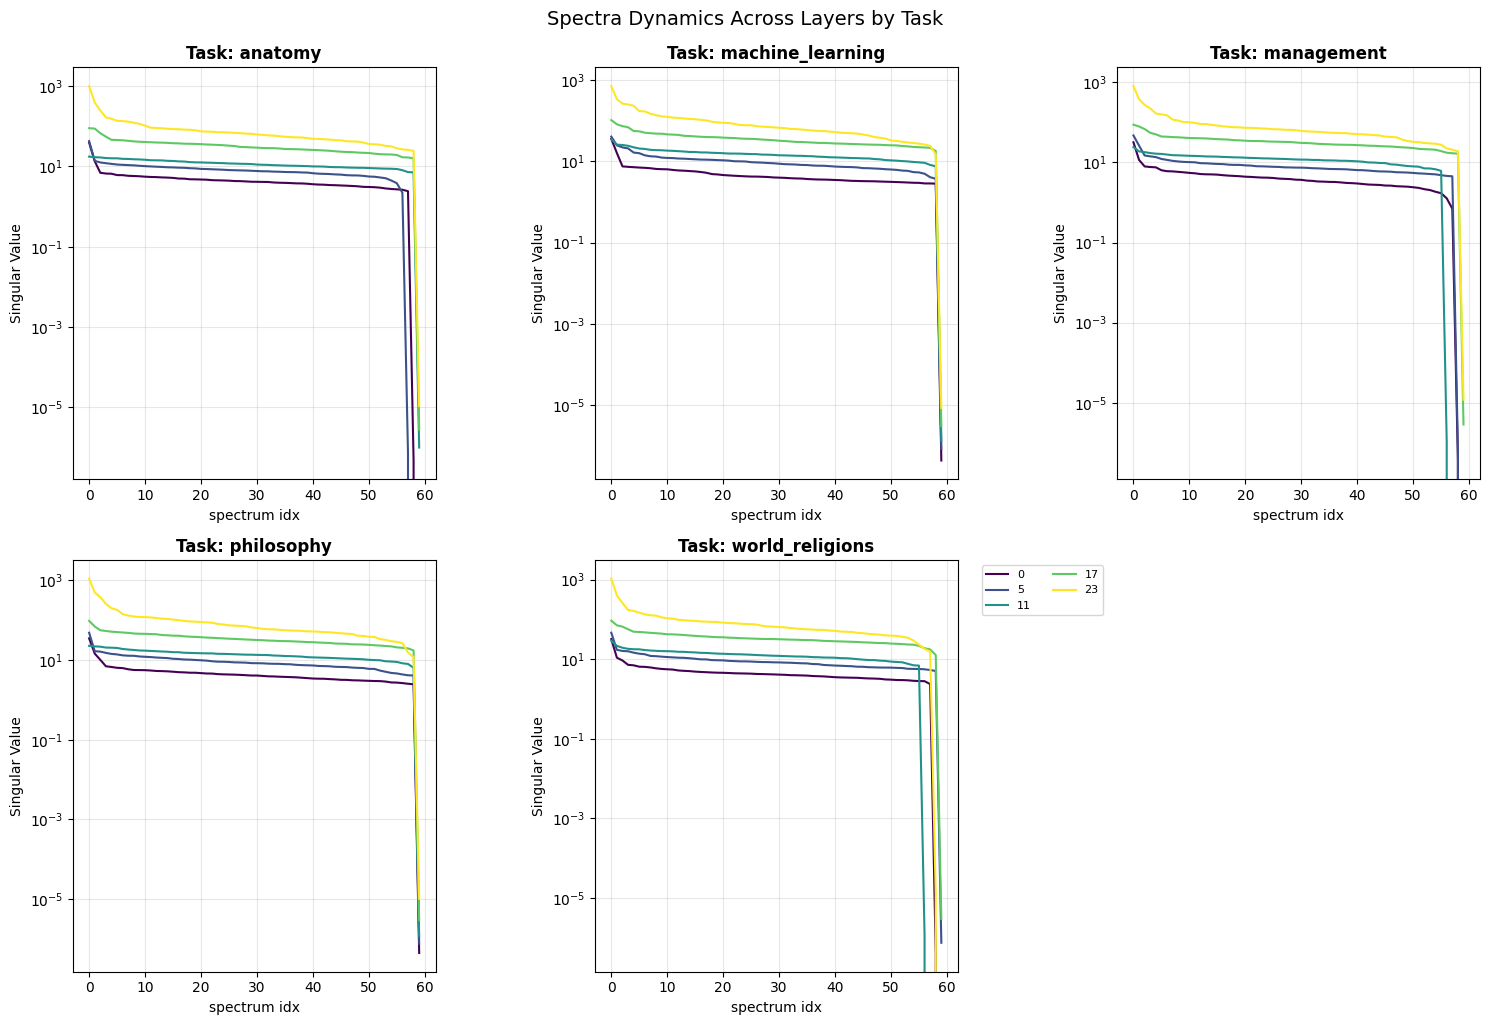

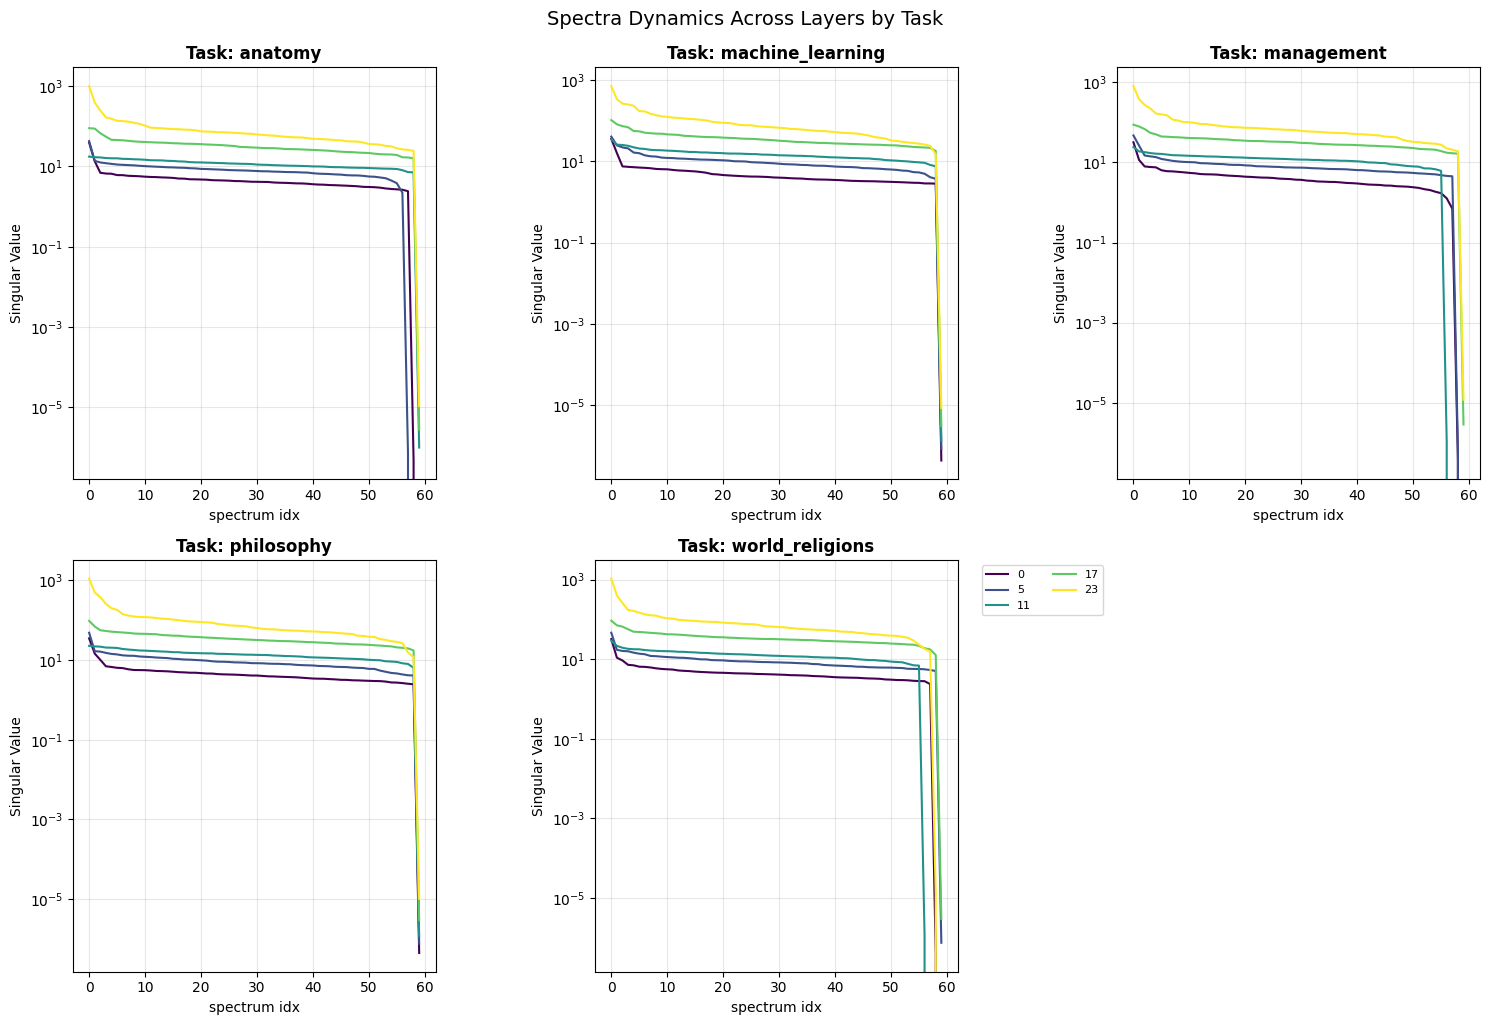

In [58]:
plot_task_dynamics_line(spectra_maxl2)

In [58]:
spectra_mean

,task,layer,0,1,2,3,4,5,6,7,...,50,51,52,53,54,55,56,57,58,59
0,anatomy,0,7.169552,3.346860,2.298078,1.883387,1.814563,1.716310,1.679368,1.590010,...,0.703951,0.699304,0.674027,0.665350,0.646503,0.616438,6.033571e-01,3.968306e-01,1.057876e-07,0.000000e+00
1,anatomy,5,9.028073,7.696976,6.180465,5.683991,5.214622,4.897239,4.546958,3.916657,...,1.717697,1.680403,1.618854,1.600203,1.543817,1.242742,9.656022e-01,2.389105e-07,0.000000e+00,0.000000e+00
2,anatomy,11,10.257659,9.116542,8.646524,8.377979,7.459891,7.232668,6.889754,6.475556,...,2.453585,2.360991,2.250088,2.166862,2.097177,2.052099,1.964189e+00,1.800214e+00,1.646650e+00,3.698813e-07
3,anatomy,17,59.074844,24.044577,21.870884,19.246273,19.170033,18.424658,17.331606,17.192919,...,6.597439,6.245894,5.998703,5.806387,5.475892,5.029548,4.968350e+00,4.663882e+00,4.304518e+00,9.806810e-07
4,anatomy,23,428.831604,198.529022,142.888290,80.457626,53.585659,50.411945,42.647888,39.551819,...,12.197629,11.729378,11.582642,10.708076,10.050405,8.827268,8.010759e+00,7.057882e+00,6.656148e+00,4.348248e-06
5,machine_learning,0,4.265631,2.627590,2.008016,1.766034,1.307342,1.268831,1.243259,1.083303,...,0.471285,0.460642,0.432732,0.429144,0.410946,0.406180,3.944512e-01,3.708346e-01,3.592506e-01,8.085431e-08
6,machine_learning,5,6.620951,5.983504,4.965361,3.792350,3.619047,3.526004,3.322526,3.273548,...,1.325737,1.312679,1.294817,1.248694,1.236486,1.230856,1.183771e+00,1.151800e+00,1.036094e+00,1.858878e-07
7,machine_learning,11,8.324896,7.496268,5.890488,5.639812,5.600858,5.386900,5.245904,5.080643,...,2.323598,2.180229,2.151682,2.021076,1.932986,1.921966,1.826902e+00,1.648884e+00,1.574343e+00,3.103118e-07
8,machine_learning,17,66.922379,21.907837,19.053755,16.758427,15.717463,14.215767,11.323240,10.848814,...,4.731164,4.699999,4.534896,4.047247,3.900381,3.684235,3.541437e+00,3.457165e+00,3.423158e+00,7.633528e-07
9,machine_learning,23,419.275879,214.298325,164.770264,82.995895,52.631428,49.548481,44.895809,39.343678,...,7.099150,7.002944,6.752243,6.148623,5.767718,5.490307,5.349098e+00,5.091439e+00,4.316859e+00,3.774599e-06


In [59]:
cat_cols = ['layer', 'task']
difference = (-(spectra_mean.set_index(cat_cols) - spectra_maxl2.set_index(cat_cols))).reset_index()

In [60]:
difference

,layer,task,0,1,2,3,4,5,6,7,...,50,51,52,53,54,55,56,57,58,59
0,0,anatomy,32.218090,10.155708,4.649080,4.771924,4.762634,4.369504,4.388423,4.252723,...,2.375359,2.337809,2.289923,2.163734,2.097321,2.072521,2.020779e+00,2.024846e+00,3.667990e-07,-0.000000e+00
1,5,anatomy,33.666202,6.063293,6.385436,6.350854,6.357425,6.257405,6.413661,6.866850,...,3.886661,3.858567,3.695127,3.485972,2.924358,2.585535,1.242347e+00,4.658860e-07,-0.000000e+00,-0.000000e+00
2,11,anatomy,7.299941,7.877267,8.098526,7.808563,8.491418,8.691713,8.569778,8.885464,...,6.652150,6.647835,6.654409,6.640203,6.661496,6.576361,6.109600e+00,5.431870e+00,5.467155e+00,6.234830e-07
3,17,anatomy,30.610405,63.649195,45.411755,35.883770,26.814957,27.108019,27.512526,26.254969,...,14.995493,14.569479,14.203314,14.130519,14.378327,14.248381,1.197095e+01,1.206632e+01,1.166997e+01,1.782492e-06
4,23,anatomy,576.670105,192.391602,104.576218,86.222641,100.118992,86.716625,92.004211,91.017502,...,24.171344,23.965237,23.221668,21.762071,21.623805,19.484376,1.849808e+01,1.886836e+01,1.763504e+01,6.380919e-06
5,0,machine_learning,31.719461,13.429083,5.513294,5.571852,5.878991,5.776741,5.691382,5.693601,...,2.656426,2.633140,2.626915,2.586874,2.562071,2.551949,2.470874e+00,2.488093e+00,2.472238e+00,3.473487e-07
6,5,machine_learning,34.192320,18.759014,17.140800,17.058675,12.875479,12.373791,10.767515,10.062742,...,4.977471,4.863585,4.638865,4.598721,4.199098,4.114187,3.781908e+00,2.923086e+00,2.687396e+00,6.362859e-07
7,11,machine_learning,26.624208,18.369861,19.413538,18.563885,16.586213,15.328605,14.999690,14.162510,...,8.264717,8.239925,8.010414,7.953830,7.729641,7.532725,7.395482e+00,6.529022e+00,5.985610e+00,9.923094e-07
8,17,machine_learning,36.928154,59.965858,54.671885,52.554569,40.185895,40.806980,39.544191,38.570284,...,20.139189,20.051698,19.393763,19.362644,18.799736,18.597751,1.847117e+01,1.813839e+01,1.456739e+01,2.253352e-06
9,23,machine_learning,297.618042,125.701981,99.753784,169.646317,180.877560,123.609829,125.013218,109.509777,...,25.642363,24.988910,23.639479,23.033640,22.502450,21.844002,2.067531e+01,1.893873e+01,1.068796e+01,4.678265e-06


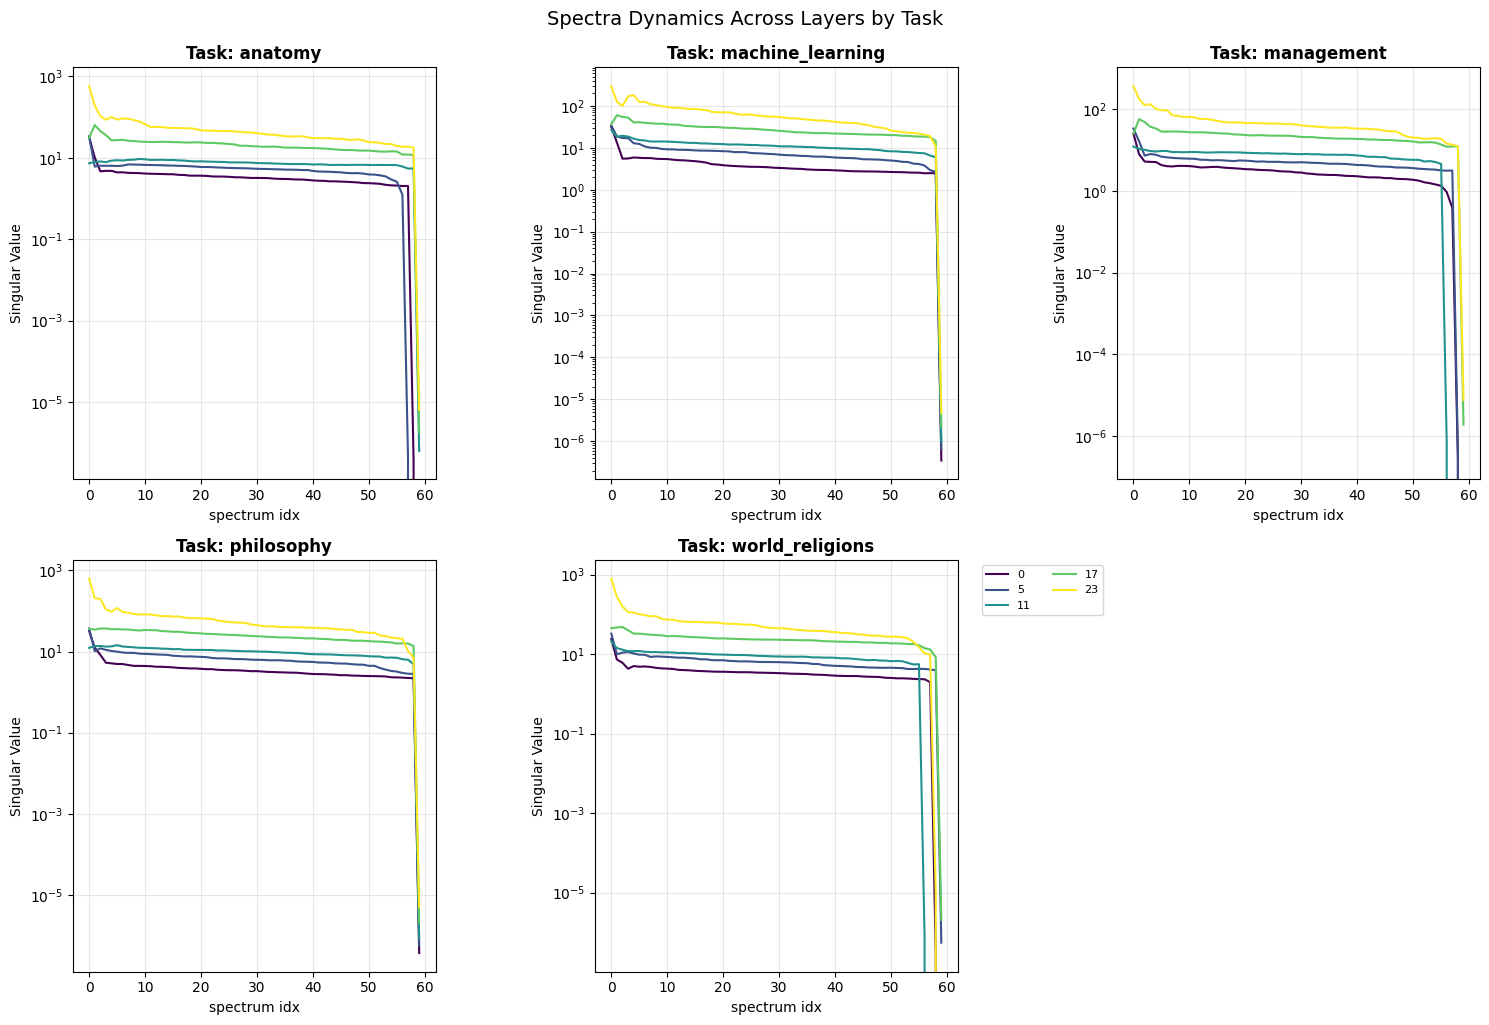

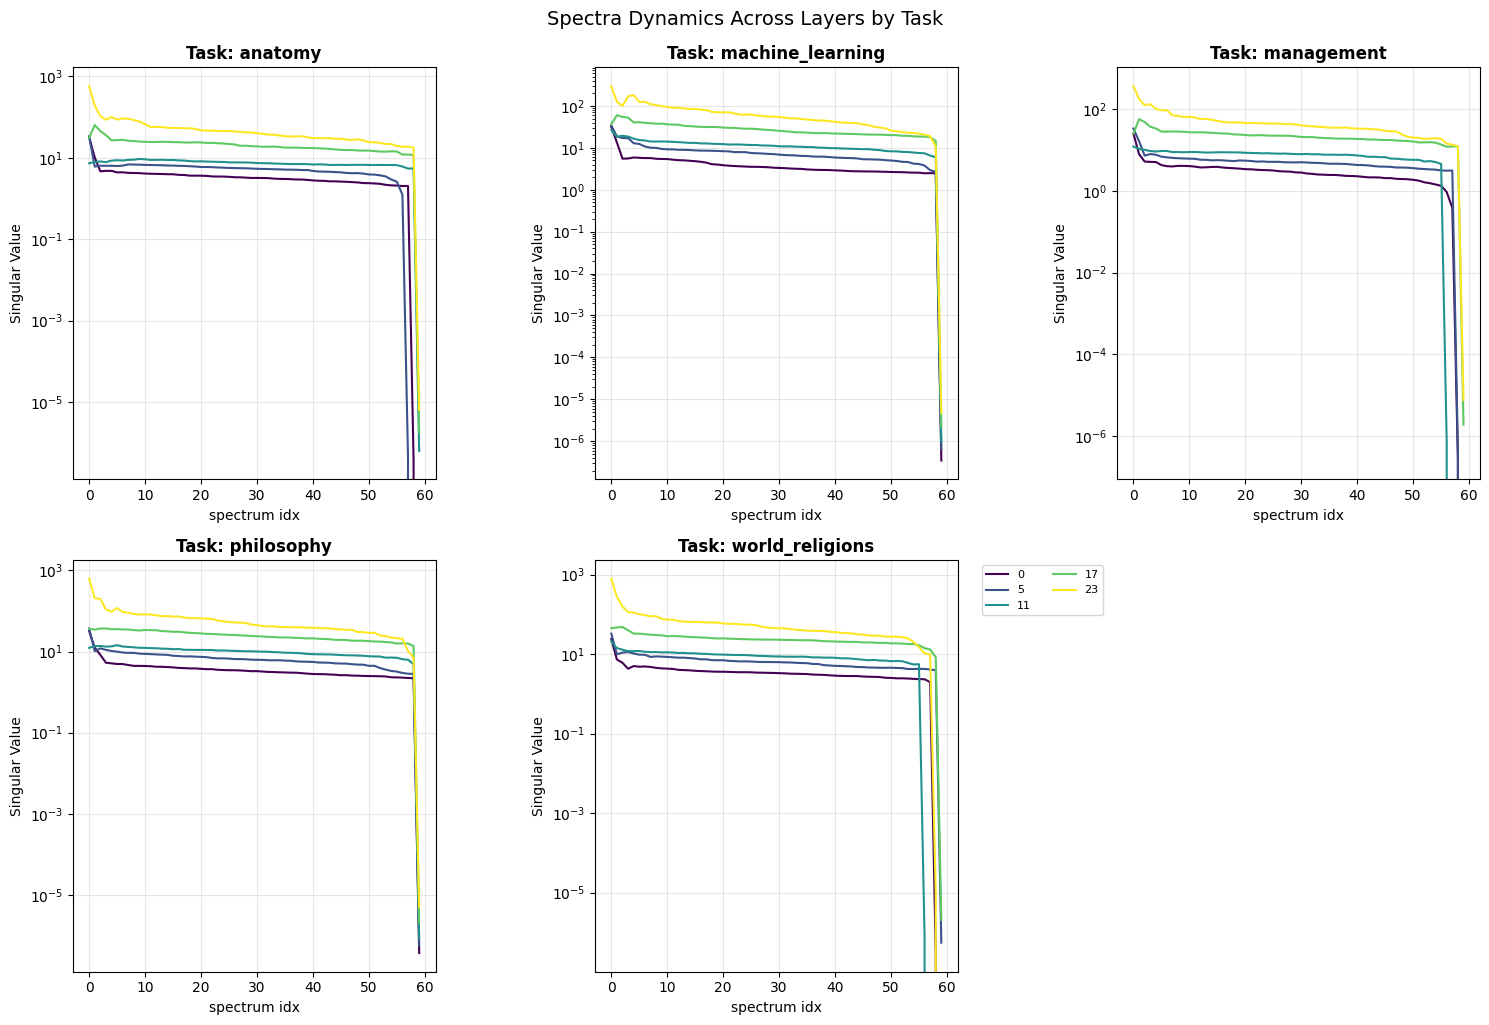

In [61]:
plot_task_dynamics_line(difference, log=True)

## Spectra centering

In [59]:
embeddings = get_tasks_expert_embeddings(parser, ["anatomy", 
            # "conceptual_physics",
            # "human_sexuality",
            "machine_learning", 
            "management", 
            # "marketing", 
            # "nutrition",
             "philosophy",
            # "us_foreign_policy",
              "world_religions"], 'mean', range(60))

anatomy !!!
machine_learning !!!
management !!!
philosophy !!!
world_religions !!!


In [60]:
E = get_expert_matrix(embeddings, 'anatomy', 0).astype(float)

In [61]:
E -= E.mean(axis=0)

In [62]:
E

array([[ 0.00096337, -0.01892106,  0.04339094, ..., -0.0321806 ,
        -0.00013974, -0.02045744],
       [-0.00811179,  0.01761611, -0.00072508, ..., -0.03715497,
         0.03804157,  0.00636369],
       [-0.05928214,  0.00598701,  0.00273008, ...,  0.014435  ,
         0.00484607, -0.01778716],
       ...,
       [ 0.00337045,  0.02276595, -0.02284746, ..., -0.00667935,
        -0.01965191,  0.01321107],
       [-0.00401099,  0.01311477,  0.01149244, ...,  0.00288982,
         0.01333759,  0.01363069],
       [ 0.00227181, -0.00862901,  0.01998396, ..., -0.0043829 ,
        -0.01293805,  0.00179368]], shape=(59, 2048))

In [66]:
U, S, Vh = np.linalg.svd(E)

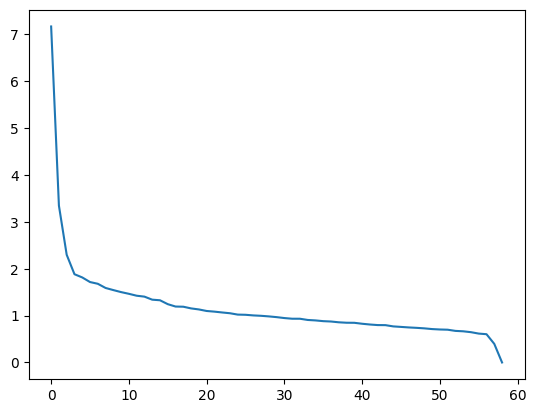

In [67]:
plt.plot(S)

In [68]:
def sisi_ratio_trunc(S, gamma=1.2):
    ratios = np.roll(S, 1) / S
    ratios[-1] = 1.
    ratios[0] = float('inf')
    indices = np.where(ratios < gamma)[0]
    if len(indices):
        return indices[0]
    else:
        return 1

def median_ratio_trunc(S, gamma=1.5):
    indices = np.where(S / np.median(S) < gamma)[0]
    if len(indices):
        return indices[0]
    else:
        return 1
    

In [69]:
def project_experts(E, mode='sisi', threshold=None):
    E = E - E.mean(axis=0)
    U, S, Vh = np.linalg.svd(E)
    if mode == 'sisi':
        threshold = threshold or 1.2
        k = sisi_ratio_trunc(S, threshold)
    elif mode == 'median':
        threshold = threshold or 1.5
        k = median_ratio_trunc(S, threshold)
    else:
        raise ValueError(f'Unknown truncation mode `{mode}`. Available [median, sisi]')
    Y = U[:, :k] * S[None, :k]
    assert Y is not None
    return Y 

In [70]:
def cluster_experts(embeddings: pd.DataFrame, clusterer, task=None, layer=0, mode='sisi', threshold=None):
    # if n_clusters is None: 
    #     n_clusters 
    embeddings = embeddings[embeddings.layer == layer]
    if task:
        embeddings = embeddings[embeddings.task == task]

    index_cols = ['expert', 'layer', 'task']
    index = embeddings[index_cols]
    E = embeddings.drop(index_cols, axis=1)
    Y = project_experts(E.astype(float), mode, threshold)
    clusterer.fit(Y)
    index.loc[:, 'label'] = clusterer.labels_
    return index, Y 




In [107]:
from functools import partial 
from sklearn.cluster import SpectralClustering

N_EXPERTS_MAX = 60
N_CLUSTERS1 = N_EXPERTS_MAX // 2
N_CLUSTERS2 = N_EXPERTS_MAX // 4

clustering_dict = {
    # Partitioning methods
    f'kmeans_{N_CLUSTERS1}': partial(KMeans, n_clusters=N_CLUSTERS1, random_state=42),
    f'kmeans_{N_CLUSTERS2}': partial(KMeans, n_clusters=N_CLUSTERS2, random_state=42),
    f'kmeans_{N_CLUSTERS1}': partial(KMeans, n_clusters=N_CLUSTERS1, random_state=42),
    f'kmeans_plusplus_{N_CLUSTERS2}': partial(KMeans, n_clusters=N_CLUSTERS2, init='k-means++', random_state=42),
    
    # Hierarchical methods
    f'ward_{N_CLUSTERS1}': partial(AgglomerativeClustering, n_clusters=N_CLUSTERS1, linkage='ward'),
    f'ward_{N_CLUSTERS2}': partial(AgglomerativeClustering, n_clusters=N_CLUSTERS2, linkage='ward'),
    
    # Density-based methods
    f'dbscan_strict': partial(DBSCAN, eps=0.3, min_samples=2),
    f'dbscan_moderate': partial(DBSCAN, eps=0.5, min_samples=2),
    f'dbscan_loose': partial(DBSCAN, eps=0.7, min_samples=2),
    f'optics_default': partial(OPTICS, min_samples=2, xi=0.05),
    
    # Graph-based methods
    f'spectral_{N_CLUSTERS2}': partial(SpectralClustering, n_clusters=N_CLUSTERS2, affinity='rbf', random_state=42),
    f'spectral_{N_CLUSTERS2}': partial(SpectralClustering, n_clusters=N_CLUSTERS2, affinity='nearest_neighbors', random_state=42),
    
    # Grid-based methods
    f'birch_{N_CLUSTERS1}': partial(Birch, n_clusters=N_CLUSTERS1),
    f'birch_{N_CLUSTERS2}': partial(Birch, n_clusters=N_CLUSTERS2),
}

In [108]:
from tqdm import tqdm 

LAYERS = [0, 11, 23]

for layer in tqdm(LAYERS, desc='layer:'):
    for name, clusterer in tqdm(clustering_dict.items(), desc='clustering:'):
        try:
            I, Y = cluster_experts(embeddings, clusterer(), layer=layer)
            I.to_csv(f'{name}_{layer}_labels.csv')
            np.save(f'{name}_{layer}_emb.npy', Y)
        except Exception as x:
            print(x)
        

layer::   0%|          | 0/3 [00:00<?, ?it/s]/tmp/ipykernel_19185/3607910665.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  index.loc[:, 'label'] = clusterer.labels_
/tmp/ipykernel_19185/3607910665.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  index.loc[:, 'label'] = clusterer.labels_
/tmp/ipykernel_19185/3607910665.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the do

In [109]:
import numpy as np
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score, fowlkes_mallows_score,
    homogeneity_score, completeness_score, v_measure_score,
    adjusted_mutual_info_score
)

METRICS = dict(zip(['silhouette', 'calinski_harabasz', 'davies_bouldin'], [silhouette_score, calinski_harabasz_score, davies_bouldin_score]))

def estimate_clustering_quality(X, labels, y_true=None):
    """
    Estimate clustering quality using various internal and external metrics.
    
    Parameters:
    -----------
    X : array-like of shape (n_samples, n_features)
        The data points used for clustering
    labels : array-like of shape (n_samples,)
        Cluster labels for each sample
    y_true : array-like of shape (n_samples,), optional
        True labels for external validation
    metrics : str or list, default='all'
        Metrics to compute. Options:
        - 'all': compute all applicable metrics
        - 'internal': only internal metrics (no ground truth needed)
        - 'external': only external metrics (requires y_true)
        - list: specific metrics like ['silhouette', 'adjusted_rand']
    
    Returns:
    --------
    dict : Dictionary containing computed metrics
    """
    results = {name: func(X, labels=labels) for name, func in METRICS.items()}
    
    return results

In [110]:
internal_metrics = ['silhouette', 'calinski_harabasz', 'davies_bouldin']
clustering_metrics = pd.DataFrame(columns=['layer', 'name', *internal_metrics])

for layer in tqdm(LAYERS, desc='layer:'):
    for name, clusterer in tqdm(clustering_dict.items(), desc='clustering:'):
        Y = np.load(f'{name}_{layer}_emb.npy')
        I = pd.read_csv(f'{name}_{layer}_labels.csv')
        metrics = estimate_clustering_quality(Y, I['label'])
        clustering_metrics.loc[clustering_metrics.shape[0], :] = (layer, name, *[metrics[m] for m in internal_metrics])


layer:: 100%|██████████| 3/3 [00:00<00:00, 21.99it/s]


In [111]:
import plotly.express as px

# Reset index to access MultiIndex levels
df_reset = clustering_metrics.groupby(['layer', 'name']).aggregate('mean').reset_index()


def scatter_cluster_metrics(df_reset):
    # Create scatter plot with color by layer
    fig = px.scatter(
        df_reset,
        x='silhouette',
        y='calinski_harabasz',
        color='layer',  # Color by layer
        text='name',    # Annotations from the 'name' level
        title='Scatter Plot: Silhouette vs Calinski-Harabasz (Colored by Layer)',
        labels={
            'silhouette': 'Silhouette Score',
            'calinski_harabasz': 'Calinski-Harabasz Score',
            'layer': 'Layer'
        },
        color_discrete_sequence=px.colors.qualitative.Set1,  # Custom color palette
        hover_data={'layer': True, 'name': True, 'silhouette': ':.3f', 'calinski_harabasz': ':.3f'}
    )

    # Customize text annotations
    fig.update_traces(
        textposition='top center',
        textfont=dict(size=10, color='black'),
        marker=dict(size=12, opacity=0.8, line=dict(width=1, color='white'))
    )

    # Update layout for better appearance
    fig.update_layout(
        width=900,
        height=600,
        hovermode='closest',
        legend_title_text='Layer',
        legend=dict(
            yanchor="top",
            y=0.99,
            xanchor="left",
            x=0.01,
            bgcolor='rgba(255,255,255,0.8)'
        )
    )
    return fig

fig = scatter_cluster_metrics(df_reset)
fig.show()

расстояние между кластерами / расстояние внутри кластеров | расстояние между точкой и ближайшим кластером / точкой и другими точками

In [112]:
k = 3 

top_approaches = clustering_metrics.groupby(['name']).aggregate('mean').sort_values(['silhouette'], ascending=[False]).reset_index().iloc[:k, 0]

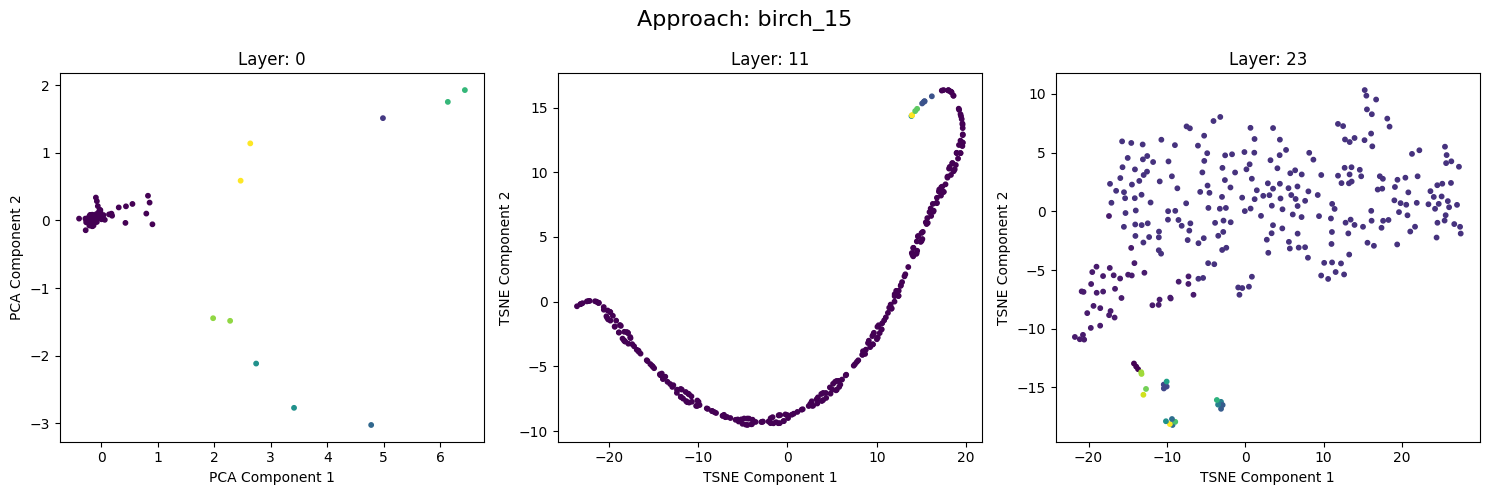

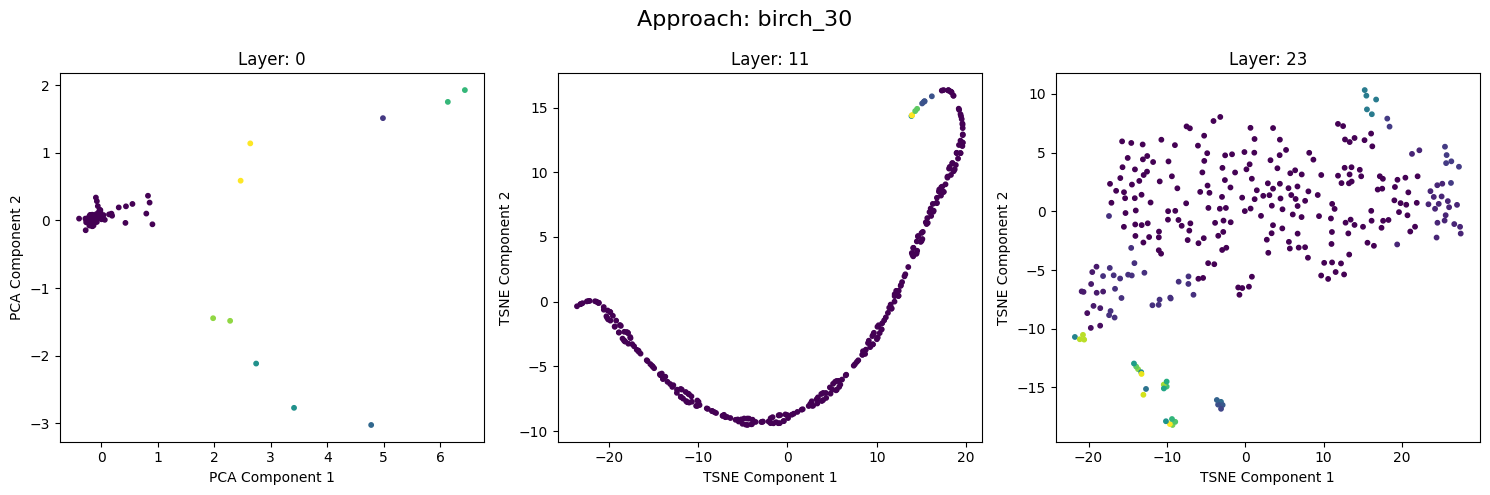

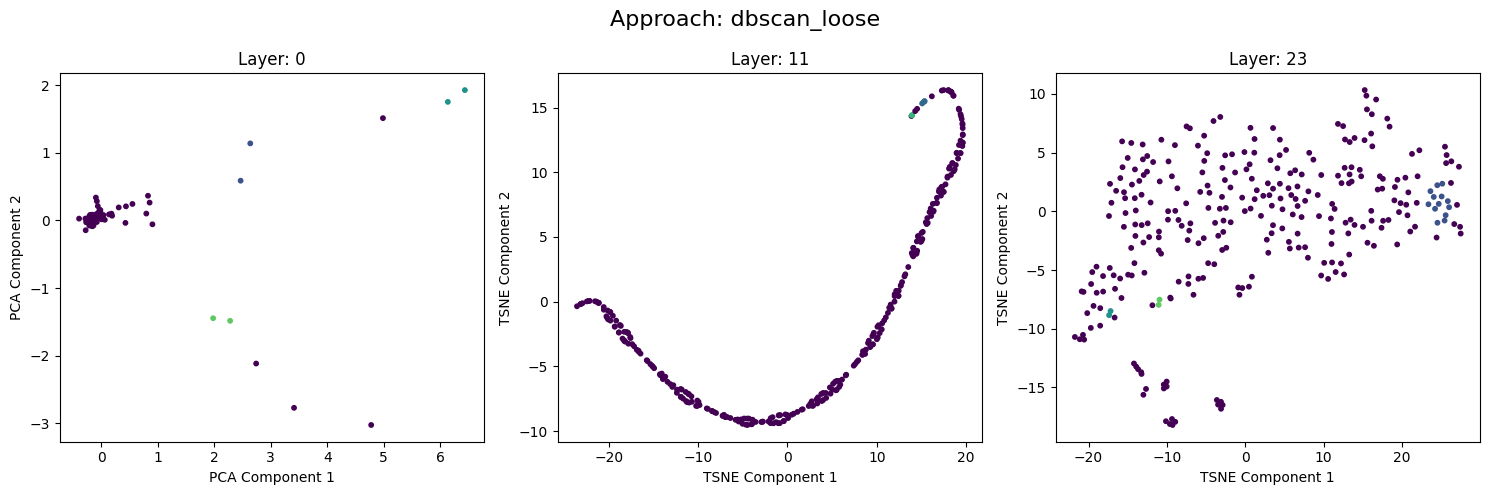

In [116]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.manifold import TSNE

for approach in top_approaches:
    # Create subplots: 1 row, number of columns = number of layers
    fig, axes = plt.subplots(1, len(LAYERS), figsize=(5 * len(LAYERS), 5))
    
    # If there's only one layer, axes is not iterable, so wrap it in a list
    if len(LAYERS) == 1:
        axes = [axes]
    
    for ax, layer in zip(axes, LAYERS):
        # Load embeddings
        Y = np.load(f'{approach}_{layer}_emb.npy')
        
        # Load labels for this specific layer
        labelling = pd.read_csv(f'{approach}_{layer}_labels.csv', index_col=0)
        
        # Apply t-SNE
        is_tsne = 'PCA'
        if Y.shape[-1] != 2:
            transformed = TSNE(random_state=1, init='random').fit_transform(Y)
            is_tsne = 'TSNE'
        else:
            transformed = Y
        
        # Get unique labels and create colormap
        n_colors = labelling['label'].nunique() - 1
        colormap = plt.get_cmap('viridis')
        
        # Map labels to colors
        c = [colormap(i / n_colors) for i in labelling['label'].values]
        
        # Plot
        ax.scatter(transformed[:, 0], transformed[:, 1], c=c, alpha=1, s=10)
        ax.set_title(f'Layer: {layer}')

        ax.set_xlabel(f'{is_tsne} Component 1')
        ax.set_ylabel(f'{is_tsne} Component 2')
    
    # Set overall figure title
    fig.suptitle(f'Approach: {approach}', fontsize=16)
    plt.tight_layout()
    plt.show()

In [114]:
plt.get_cmap('viridis')(0.)

(np.float64(0.267004),
 np.float64(0.004874),
 np.float64(0.329415),
 np.float64(1.0))

### Cooccurence 

In [12]:
import torch

def count_pair_occurrences(indices):
    """
    Count occurrences of each unordered index pair across all rows.

    Args:
        indices: torch.Tensor of shape (n_samples, k), dtype=torch.long,
                 each row contains k indices (e.g., from torch.topk).

    Returns:
        unique_pairs: torch.Tensor of shape (num_unique_pairs, 2), each row is a pair (i, j) with i < j.
        counts: torch.Tensor of shape (num_unique_pairs,), counts for each pair.
    """
    n, k = indices.shape
    device = indices.device

    # All unordered column index pairs (i, j) with i < j
    col_pairs = torch.combinations(torch.arange(k, device=device), r=2)  # (m, 2)

    # Gather actual index values for these column pairs across all rows
    all_pairs = indices[:, col_pairs]  # (n, m, 2)

    # Sort each pair so that the smaller index comes first (canonical order)
    sorted_pairs, _ = torch.sort(all_pairs, dim=-1)  # (n, m, 2)

    # Flatten to a list of all pairs
    flat_pairs = sorted_pairs.view(-1, 2)  # (n*m, 2)

    # Count unique pairs
    unique_pairs, counts = torch.unique(flat_pairs, dim=0, return_counts=True)

    return unique_pairs, counts

In [23]:
G = parser.parse_gate(0, 'anatomy')

In [24]:
G_k = torch.topk(G, k=4).indices

In [25]:
pair, coocurrence = count_pair_occurrences(G_k)

(array([503.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   6.]),
 array([  1. ,  25.3,  49.6,  73.9,  98.2, 122.5, 146.8, 171.1, 195.4,
        219.7, 244. ]),
 <BarContainer object of 10 artists>)

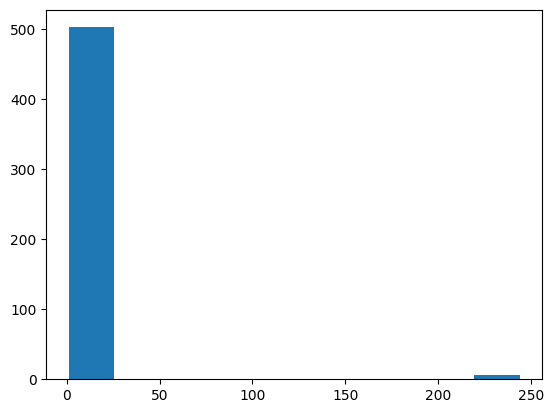

In [26]:
plt.hist(coocurrence.flatten())

In [27]:
import torch
from collections import Counter

def count_pair_missing(indices, co_occurrence_pairs=None, co_occurrence_counts=None):
    """
    For each unordered pair (i, j) with i < j, compute:
        - count_i_without_j : rows where i appears but j does not
        - count_j_without_i : rows where j appears but i does not

    Args:
        indices: torch.Tensor of shape (n_samples, k), dtype=torch.long
        co_occurrence_pairs: optional tensor of shape (num_pairs, 2) from previous function
        co_occurrence_counts: optional tensor of shape (num_pairs,) – if given, use them
                               to avoid recomputing co‑occurrences.

    Returns:
        result: dict or list of tuples (pair, count_i_without_j, count_j_without_i)
    """
    n, k = indices.shape
    device = indices.device

    # 1. Compute individual frequencies (how many rows contain each index)
    unique_vals, freq = torch.unique(indices, return_counts=True)
    freq_dict = {int(v): int(f) for v, f in zip(unique_vals, freq)}

    # 2. Get co‑occurrence information if not provided
    if co_occurrence_pairs is None or co_occurrence_counts is None:
        # Use the previous function (assume it's defined)
        co_occurrence_pairs, co_occurrence_counts = count_pair_occurrences(indices)

    # 3. For each pair, compute the missing counts
    result = []
    for (i, j), c in zip(co_occurrence_pairs.tolist(), co_occurrence_counts.tolist()):
        i, j = int(i), int(j)
        freq_i = freq_dict.get(i, 0)
        freq_j = freq_dict.get(j, 0)
        count_i_without_j = freq_i - c
        count_j_without_i = freq_j - c
        result.append(((i, j), count_i_without_j, count_j_without_i))

    return result


In [28]:
# First get co‑occurrence pairs and counts
pairs, counts = count_pair_occurrences(G_k)

# Then get the "missing" counts
missing_stats = count_pair_missing(G_k, pairs, counts)

In [29]:
def coocurence_metric(gate, k=4):
    G_k = torch.topk(gate, k=k).indices
    pairs, counts = count_pair_occurrences(G_k)
    missing_stats = count_pair_missing(G_k, pairs, counts)
    
    metrics = dict(zip((tuple(p) for p in pairs.tolist()), counts))
    for pair, i_not_j, j_not_i in missing_stats:
        metrics[pair] = metrics.get(pair, 0) ** 2 / (1 + i_not_j + j_not_i)
    return metrics

In [30]:
cooc = coocurence_metric(G)

In [31]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def build_heatmap_matrix(pair_dict, num_experts, device='cpu'):
    """
    Convert a dictionary of (i, j) -> value into a symmetric 2D matrix.

    Args:
        pair_dict: dict with keys as tuples (i, j) and values as torch.Tensor scalars
        num_experts: total number of experts (indices from 0 to num_experts-1)
        device: torch device for the output tensor

    Returns:
        matrix: torch.Tensor of shape (num_experts, num_experts)
    """
    matrix = torch.zeros((num_experts, num_experts), device=device)
    for (i, j), val in pair_dict.items():
        # Ensure val is a scalar tensor (detach, move to correct device)
        v = val.to(device).detach()
        matrix[i, j] = v
        matrix[j, i] = v   # symmetric for heatmap
    return matrix


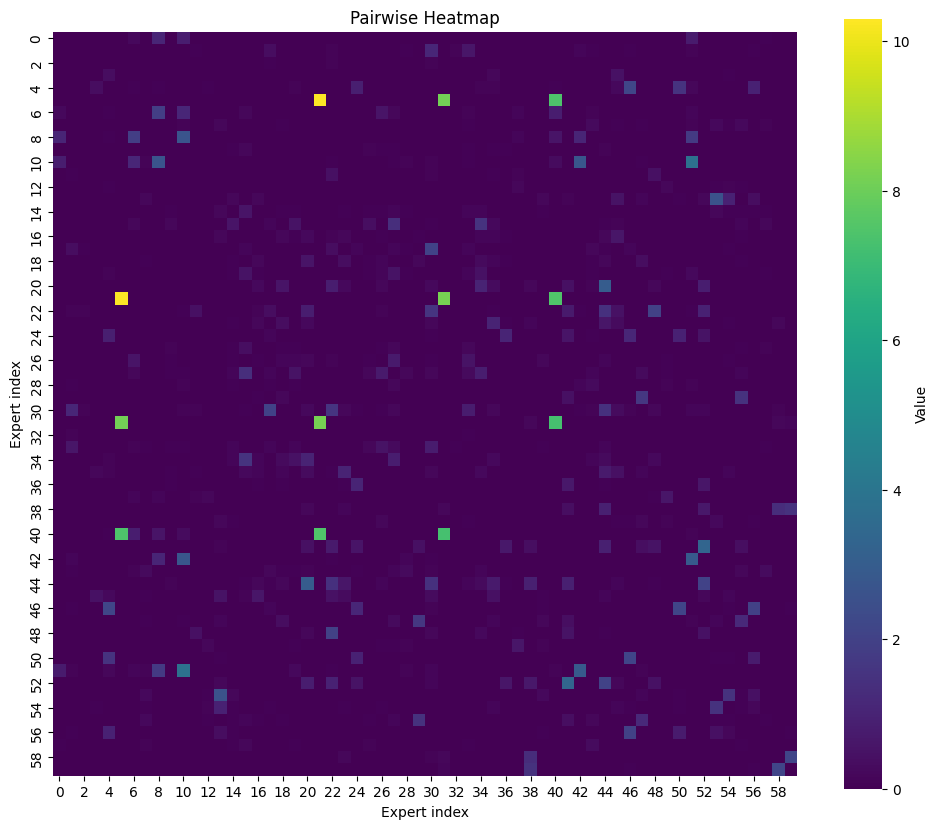

In [32]:
max_experts = 60  # given, adjust as needed
heatmap_mat = build_heatmap_matrix(cooc, max_experts)

# Plotting (if you have matplotlib/seaborn)
plt.figure(figsize=(12, 10))
sns.heatmap(np.log(1 + heatmap_mat.numpy()), cmap='viridis', square=True, cbar_kws={'label': 'Value'})
plt.title('Pairwise Heatmap')
plt.xlabel('Expert index')
plt.ylabel('Expert index')
plt.show()

In [34]:
(heatmap_mat > 1.).to(int).sum(0)

tensor([3, 1, 0, 0, 4, 3, 3, 0, 5, 0, 5, 0, 0, 2, 0, 2, 0, 1, 0, 0, 4, 3, 5, 1,
        4, 0, 0, 2, 0, 2, 5, 3, 0, 1, 3, 1, 1, 0, 3, 0, 4, 2, 3, 0, 6, 0, 4, 2,
        1, 0, 4, 4, 4, 2, 2, 2, 3, 0, 2, 2])

(array([20.,  7., 11.,  9.,  8.,  5.]),
 array([0., 1., 2., 3., 4., 5., 6.]),
 <BarContainer object of 6 artists>)

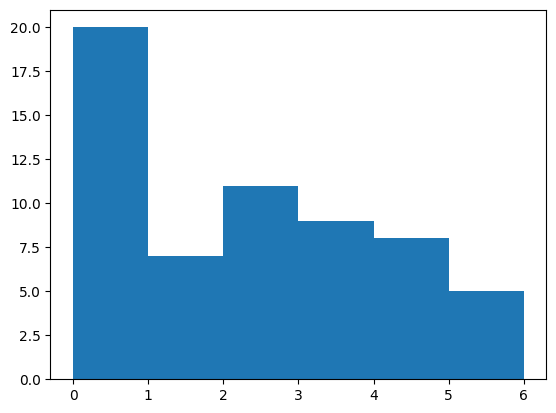

In [33]:
plt.hist((heatmap_mat > 1.).to(int).sum(0), bins=6)

In [ ]:
from scipy.stats import kendalltau
import itertools

def kendall_correlation(list1, list2):
    """
    Compute Kendall's tau correlation between two lists of items.
    Items can be any hashable type (int, tuple, string, etc.).

    Args:
        list1: first ordered list (e.g., ranking)
        list2: second ordered list

    Returns:
        tau: Kendall correlation coefficient (float)
        p_value: two-tailed p-value (if scipy is used, else None)

    Notes:
        - Only items present in both lists are considered (intersection).
        - Ties are handled appropriately (tau-b version).
    """
    # Convert to lists of items (tuples are fine)
    items1 = list(list1)
    items2 = list(list2)

    # Keep only items that appear in both lists (for a common set)
    common = set(items1) & set(items2)
    if not common:
        raise ValueError("No common items between the two lists")

    # Filter each list to only common items, preserving original order
    filtered1 = [x for x in items1 if x in common]
    filtered2 = [x for x in items2 if x in common]

    # If lengths differ after filtering, it means some common items are missing
    # (should not happen if we filter both by the same common set, but double-check)
    if len(filtered1) != len(filtered2):
        raise ValueError("Internal error: filtered lists have different lengths")

    # Map each item to its position in the second list
    pos_in_2 = {item: idx for idx, item in enumerate(filtered2)}

    # Convert first list into ranks according to second list's order
    # rank = position of item in filtered2 (0-based)
    ranks = [pos_in_2[item] for item in filtered1]

    # Now we have two sequences: natural order 0,1,2,... and the ranks above
    # Kendall tau between [0,1,2,...] and ranks        # Use scipy for accuracy and p-value
    tau, p_value = kendalltau(list(range(len(ranks))), ranks)
    return tau, p_value



kendal_ordering = pd.DataFrame(columns=['layer', 'task', 'values'])
tasks = SELECTED_TASKS
for layer_number in [0, 11, 23]:

    for task in tasks:
        G = parser.parse_gate(layer=layer_number, task=task)
        cooc = coocurence_metric(G)
        ordered_values = sorted(cooc, key=cooc.get)
        kendal_ordering.loc[kendal_ordering.shape[0]] = (layer_number, task, ordered_values)


In [137]:
import pandas as pd
from scipy.stats import kendalltau
from itertools import combinations

def kendall_correlation_two_lists(list1, list2):
    """
    Compute Kendall's tau between two lists of items (hashable).
    Only common items are considered; relative order is preserved.
    """
    # Keep only items present in both lists
    common = set(list1) & set(list2)
    if len(common) < 2:
        return float('nan')  # Not enough common pairs to compute correlation
    
    # Filter each list to common items (preserve order)
    filtered1 = [x for x in list1 if x in common]
    filtered2 = [x for x in list2 if x in common]
    
    # Map second list order to ranks
    pos_in_2 = {item: idx for idx, item in enumerate(filtered2)}
    ranks1 = [pos_in_2[item] for item in filtered1]
    
    # Kendall tau between natural order (0..n-1) and ranks1
    tau, _ = kendalltau(list(range(len(ranks1))), ranks1)
    return tau, _

def pairwise_task_correlations(df):
    """
    For each layer, compute Kendall correlation for every pair of tasks.
    
    df : DataFrame with columns ['layer', 'task', 'values']
         values : list of tuples (e.g., from topk operation)
    
    Returns: DataFrame with columns ['layer', 'task1', 'task2', 'correlation']
    """
    results = []
    for layer, group in df.groupby('layer'):
        # Create mapping task -> list of tuples
        task_dict = dict(zip(group['task'], group['values']))
        tasks = list(task_dict.keys())
        
        for task1, task2 in combinations(tasks, 2):
            list1 = task_dict[task1]
            list2 = task_dict[task2]
            corr, pvalue = kendall_correlation_two_lists(list1, list2)
            results.append({
                'layer': layer,
                'task1': task1,
                'task2': task2,
                'correlation': corr,
                'pvalue': pvalue
            })
    return pd.DataFrame(results)

# Example usage (assuming your dataframe is named df)
corr_df = pairwise_task_correlations(kendal_ordering)
print(corr_df)

    layer             task1             task2  correlation  pvalue
0       0           anatomy  machine_learning          1.0     0.0
1       0           anatomy        management          1.0     0.0
2       0           anatomy        philosophy          1.0     0.0
3       0           anatomy   world_religions          1.0     0.0
4       0  machine_learning        management          1.0     0.0
5       0  machine_learning        philosophy          1.0     0.0
6       0  machine_learning   world_religions          1.0     0.0
7       0        management        philosophy          1.0     0.0
8       0        management   world_religions          1.0     0.0
9       0        philosophy   world_religions          1.0     0.0
10     11           anatomy  machine_learning          1.0     0.0
11     11           anatomy        management          1.0     0.0
12     11           anatomy        philosophy          1.0     0.0
13     11           anatomy   world_religions          1.0    

In [147]:
embeddings

/home/leostre/Рабочий стол/MoE_Optimization/.venv/lib/python3.10/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()
/home/leostre/Рабочий стол/MoE_Optimization/.venv/lib/python3.10/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,task,layer,expert,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,...,emb_2038,emb_2039,emb_2040,emb_2041,emb_2042,emb_2043,emb_2044,emb_2045,emb_2046,emb_2047
0,anatomy,0,49,0.006840,-0.022202,0.043274,-0.008469,0.004543,0.015121,-0.022430,...,-0.038147,-0.008469,0.015121,0.013977,-0.012024,0.003902,0.009148,-0.032166,0.002834,-0.020599
1,anatomy,0,31,-0.002235,0.014336,-0.000842,-0.025787,0.003002,0.013557,0.037018,...,-0.021271,-0.040771,-0.040680,-0.039673,-0.051392,0.045013,0.009811,-0.037140,0.041016,0.006222
2,anatomy,0,30,-0.053406,0.002707,0.002613,-0.023102,0.027313,-0.064209,0.061401,...,0.055420,0.014008,-0.013977,0.007179,-0.028488,-0.042755,-0.000776,0.014450,0.007820,-0.017929
3,anatomy,0,57,0.000038,-0.030624,-0.021683,0.037384,-0.012993,-0.038940,0.008881,...,0.028015,-0.002375,-0.002161,0.020096,-0.010689,-0.002951,-0.001753,-0.021790,0.019928,0.005112
4,anatomy,0,14,-0.011681,-0.025192,0.001995,0.005089,-0.006290,0.001283,-0.017426,...,0.013863,0.008591,-0.014458,0.001797,-0.016434,-0.022263,0.001304,-0.005520,-0.010117,0.007175
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7132,world_religions,23,26,1.046875,-0.751953,-0.895996,-1.313477,0.975098,-0.298340,0.152344,...,-0.612305,0.638672,-0.439941,0.011185,-0.203247,0.820801,-0.005665,1.626953,-0.142212,-0.370117
7133,world_religions,23,31,2.867188,2.404297,2.101562,2.251953,3.876953,0.420898,-1.259766,...,-3.667969,-1.600586,-2.808594,-0.525879,-1.726562,2.720703,-3.376953,-1.629883,1.155273,2.574219
7134,world_religions,23,36,-0.194946,0.432861,0.224365,-0.137085,-0.031647,-0.570801,0.137329,...,0.298096,0.320557,0.115173,-0.019897,0.156128,0.166870,0.158325,-0.280273,0.061127,-0.440674
7135,world_religions,23,55,0.117920,0.048950,-0.250000,-0.146362,-0.036926,-0.150513,0.022461,...,-0.080688,0.040344,-0.001269,-0.132202,0.080505,0.058777,0.100220,0.001518,0.126221,-0.119812


In [151]:
embeddings.groupby(['layer', 'expert']).get_group((0, 0))

/home/leostre/Рабочий стол/MoE_Optimization/.venv/lib/python3.10/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()
/home/leostre/Рабочий стол/MoE_Optimization/.venv/lib/python3.10/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,task,layer,expert,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,...,emb_2038,emb_2039,emb_2040,emb_2041,emb_2042,emb_2043,emb_2044,emb_2045,emb_2046,emb_2047
57,anatomy,0,0,0.001865,0.009834,0.011375,-0.005096,-0.023453,0.000700,-0.006351,...,-0.017487,-0.033630,-0.001604,0.011375,0.019394,-0.004192,0.002104,0.002905,0.016312,0.013489
1483,machine_learning,0,0,-0.005547,-0.000740,0.003500,-0.007046,-0.001829,0.001836,-0.008064,...,-0.010796,0.014000,0.001930,0.005718,-0.012360,0.004230,-0.007668,0.002686,0.001263,0.000842
2921,management,0,0,-0.030777,0.033661,-0.012383,-0.009369,0.013237,-0.003056,0.012115,...,-0.007889,0.019699,0.015182,-0.016129,-0.001997,-0.017120,-0.009911,-0.030685,0.004356,0.003613
4337,philosophy,0,0,-0.017517,0.001802,-0.005840,-0.003748,0.001502,0.004429,-0.015167,...,-0.022934,0.000813,-0.008698,0.003273,-0.008011,-0.004940,-0.000002,0.003872,-0.011833,-0.002573
5770,world_religions,0,0,0.017227,0.007828,0.007099,0.001688,-0.002789,-0.006142,0.000272,...,-0.005280,0.007011,0.004326,0.002968,0.002028,0.004570,-0.009377,-0.005096,0.028793,0.016220


In [ ]:
parser.parse_experts()

In [35]:
import os
import torch

def convert_pth_to_cpu(directory: str) -> None:
    """
    Recursively walk through a directory, load all .pth files,
    move their contents to CPU, and save them back in place.

    Args:
        directory (str): Root directory to search for .pth files.
    """
    for root, _, files in os.walk(directory):
        for file in files:
            if file.endswith('.pth'):
                filepath = os.path.join(root, file)
                try:
                    # Load the file directly onto CPU
                    data = torch.load(filepath, map_location='cpu')
                    # Save back to the same path (overwrites)
                    torch.save(data, filepath)
                    print(f"Processed: {filepath}")
                except Exception as e:
                    print(f"Failed to process {filepath}: {e}")

# Example usage:
# convert_pth_to_cpu('/path/to/your/directory')

In [18]:
import numpy as np 

sample = np.random.rand(100).reshape(-1, 1)

u, s, v = np.linalg.svd(sample, full_matrices=False)

In [19]:
s

array([5.80667936])

In [20]:
v

array([[1.]])

In [21]:
np.linalg.norm(u)

np.float64(1.0)

In [7]:
u.shape

(100, 100)

In [22]:
np.abs(((u * s) - (sample))).max()

np.float64(2.220446049250313e-16)

In [ ]:
from typing import * 

def aggregated_embedding(E: np.ndarray, mode: Literal['pca', 'mean']): 
    """
    E is a embedding matrix / vector for one expert on one layer (!). 
    E size is: [n_observations x embedding_size]
    if E is a vector it would be treated as [1 x embbedding_size] matrix. 
    """
    if E.ndim == 1:
        E = E.reshape(1, -1)
    elif E.ndim > 2:
        raise ValueError('Expected vector or 2D matrix')
    
    if mode == 'mean':
        return np.mean(E, axis=0)
    elif mode == 'svd':
        m = E.mean(axis=0)
        E -= m 
        U, S, Vt = np.linalg.svd(E.T, full_matrices=False)
        one_rank_emb = U[:, 0] * S[0]
        one_rank_emb += m 
        return one_rank_emb
    else:
        raise ValueError('Expected for `mode` onw of: `pca`, `mean`')


In [19]:
from pathlib import Path 
from typing import * 
from itertools import chain
import torch

def is_gate(name: str, layer: torch.nn.Module = None):
    return name.endswith('gate')

class ExpertsLogger():
    def __init__(self, model: torch.nn.Module, layer_of_interest: Union[type, List[str]], gate_func: Callable):
        self.model = model
        self.is_gate: Callable = gate_func 
        if isinstance(layer_of_interest, type):
            self.name_to_layer = {name: layer for name, layer in model.named_modules() if isinstance(layer, layer_of_interest) or gate_func(name, layer)}
        elif isinstance(layer_of_interest(tuple, list)) and len(layer_of_interest) and isinstance(layer_of_interest[0], str):
            self.name_to_layer = {name: layer for name, layer in model.named_modules() if name in layer_of_interest}
        else: 
            raise TypeError('Unknown type of argument `layer_of_interest` passed: expected either type of expert layer or list of layers\' names (strings)')
        self.layer_to_name: Dict[torch.nn.Module, str] = {layer: name for name, layer in self.name_to_layer.items()}
        self.name_to_activation: Dict[str, torch.nn.Module] = {name: [] for name in self.name_to_layer}
        self.hooks = []
        self.reset()

    @torch.no_grad()
    def get_activations(self, example_batches):
        for batch in example_batches:
            self.model(**batch)
        return self.name_to_activation

    def _gathering_hook(self):
        def hook_function(module, input, output):
            self.name_to_activation[
                self.layer_to_name[module]
            ].append(
                output.to('cpu')
            )
            
        for layer in self.layer_to_name:
            self.hooks.append(
                layer.register_forward_hook(hook_function)
            )

    def reset(self):
        self.clean()
        self.current_forward = 0 
        self._gathering_hook()

    def clean(self):
        for hook in self.hooks:
            hook.remove()
        self.hooks = [] 



In [ ]:
from functools import partial 
from common.moe_utils import MoeHandle, discover_moe_layers

class ExpertClusterer:
    # @staticmethod
    # def is_gate(name: str, layer: torch.nn.Module = None):
    #     return name.endswith('gate')

    def __init__(self, model: torch.nn.Module, example_inputs: Iterable, ):
        self.module2name = {m: n for n, m in model.named_modules()}
        self.model = model
        self.example_inputs = example_inputs
        self.experts_logger = partial(ExpertsLogger, model=model)
        self.moe_handles: List[MoeHandle] = discover_moe_layers(model)
    
    def clusterize_layers(self,  target_layers):
        activations = self.get_activations(target_layers)
        activations = self._aggregate_length_sequence(activations)

    def _aggregate_length_sequence(self, activations):
        for name, activation_list in activations.items():
            activations[name] = torch.cat([
                a.mean(dim=0).unsqueeze(0) for a in activation_list
            ], dim=0)
        return activations

    @staticmethod
    def _get_aggregated_embedding(E: torch.Tensor, mode: Literal['pca', 'mean']): 
        """
        E is a embedding matrix / vector for one expert on one layer (!). 
        E size is: [n_observations x embedding_size]
        if E is a vector it would be treated as [1 x embbedding_size] matrix. 
        """
        if E.ndim == 1:
            E = E.reshape(1, -1)
        elif E.ndim > 2:
            raise ValueError('Expected vector or 2D matrix')
        
        if mode == 'mean':
            return torch.mean(E, dim=0)
        elif mode == 'svd':
            m = E.mean(dim=0)
            E -= m 
            U, S, Vt = torch.linalg.svd(E.T, full_matrices=False)
            one_rank_emb = U[:, 0] * S[0]
            one_rank_emb += m 
            return one_rank_emb
        else:
            raise ValueError('Expected for `mode` one of: `pca`, `mean`')
        
    @torch.no_grad()
    def get_activations(self, target_layers: List[MoeHandle]):
        if not (isinstance(target_layers, (list, tuple)) and len(target_layers)):
            raise TypeError('Expected non-empty list or tuple of MoEHandle or int')
        
        gate_names = [
            self.module2name[moe_handle.gate] for moe_handle in target_layers
        ]
        experts_names = [self.module2name[expert] for handle in target_layers for expert in handle.children()]
        experts_logger: ExpertsLogger = self.experts_logger(layer_of_interest=experts_names + gate_names)
        experts_logger.reset()
        name2activation = experts_logger.get_activations(self.example_inputs)
        return name2activation
        
        
    

### Model loading

In [9]:
from datasets import load_dataset
import pandas as pd

# Download the MMLU dataset from Hugging Face
# 'cais/mmlu' is the official repository
dataset = load_dataset("cais/mmlu", "all")  # "all" includes all subjects

/home/leostre/Рабочий стол/MoE_Optimization/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [12]:
from common.clustering_utils import get_qwen, MMLUBatchGenerator
from common.moe_utils import discover_moe_layers 

In [13]:
gen = MMLUBatchGenerator()

Initialized MMLU batch generator with 57 subjects
Split: test, Batch size: 64


In [14]:
model, tokenizer = get_qwen()

Loading checkpoint shards: 100%|██████████| 8/8 [00:16<00:00,  2.12s/it]


In [15]:
handles = discover_moe_layers(model)

In [18]:
handles[0].gate

Linear4bit(in_features=2048, out_features=60, bias=False)